# 05 – Suy luận Thống kê: Kiểm định Giả thuyết có Đối chứng (Issue #11, W9)

**Khóa học:** INFO3020 – Nhập môn Khoa học Dữ liệu (CMC University)  
**Dữ liệu nguồn:** `data/processed/air_pollution_final.parquet` (trạm NCEM/VEA 556 Nguyễn Văn Cừ, Hà Nội)  
**Quy chuẩn đối chiếu:** QCVN 05:2023/BTNMT — PM₂.₅ trung bình 24 giờ = 50 µg/m³, trung bình năm = 25 µg/m³

---

## Câu hỏi của W9

Issue #8 mô tả *phân phối* PM₂.₅. Issue #11 hỏi tiếp: những khác biệt quan sát
được trong dữ liệu **có vượt quá dao động ngẫu nhiên hay không**, và nếu có thì
lớn đến mức nào. Cụ thể:

1. Nồng độ PM₂.₅ trung bình ngày có khác nhau giữa **bốn mùa** không?
2. **Ngày làm việc** và **ngày cuối tuần** có khác nhau không?
3. Vị trí phân phối trung bình ngày nằm **trên hay dưới ngưỡng QCVN 24 giờ** (50 µg/m³)?
4. Trung bình của trung bình ngày nằm **trên hay dưới ngưỡng QCVN năm** (25 µg/m³)?

## Nguyên tắc báo cáo

Mỗi kiểm định được trình bày theo **bộ bốn bắt buộc**: thống kê kiểm định + p-value
chính xác + effect size + khoảng tin cậy 95% bootstrap. Kèm theo là H₀/H₁, lý do
chọn phép kiểm, cỡ mẫu và số quan sát bị loại. **Không** có kết luận nào chỉ dựa
vào một p-value.

## Phân biệt với các issue khác

| Nội dung | Thuộc issue | Notebook |
|---|---|---|
| Thống kê mô tả, hình dạng phân phối | #8 | `04_descriptive_stats.ipynb` |
| Hình giải thích cho báo cáo | #9 | `figures/FIG-01…07` |
| Kiểm định giả thuyết, effect size, CI | **#11** | **`05` (notebook này)** |
| Hồi quy + phân loại mất cân bằng | #12–#13 | `06`, `07` |


## 0. Thiết lập môi trường

Notebook chỉ gọi **một lần** `run_inference()` rồi tái sử dụng payload. Mọi con số
hiển thị bên dưới đọc từ payload đó — không có giá trị nào viết tay, nên chạy lại
trên dataset khác sẽ ra số khác thay vì giữ nguyên số cũ.

Hai helper định dạng `p_text` / `ci_text` được viết **cục bộ** (không import từ
`src.inference`) để cell cuối có thể đối chiếu chéo: nếu báo cáo và notebook lệch
định dạng hoặc lệch số, phép so chuỗi sẽ thất bại.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# ── Đường dẫn gốc repository ─────────────────────────────────────────────
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

from src.flag_evidence import format_int_vi, format_number_vi  # noqa: E402
from src.inference import (  # noqa: E402
    ALPHA,
    BLOCK_LENGTH_DAYS,
    DEFAULT_REPORT_PATH,
    INFERENCE_FIGURES,
    N_BOOTSTRAP,
    QCVN_2023_PM25_24H_LIMIT,
    QCVN_2023_PM25_ANNUAL_LIMIT,
    SEASON_DISPLAY_ORDER,
    SEASON_LABELS_VI,
    plot_inference_figures,
    qq_points,
    render_inference_report,
    run_inference,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 100)

# ── Định dạng cục bộ — cố ý KHÔNG dùng helper của src.inference ─────────
_SUPERSCRIPT = str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹")


def p_text(p: float) -> str:
    '''p-value: 4 chữ số thập phân, hoặc ký hiệu khoa học khi < 10⁻⁴.'''
    if p >= 1e-4:
        return f"{p:.4f}".replace(".", ",")
    exponent = int(np.floor(np.log10(p)))
    return f"{p / 10 ** exponent:.2f}".replace(".", ",") + "·10" + str(exponent).translate(_SUPERSCRIPT)


def _num(value: float, digits: int = 2) -> str:
    '''Số thập phân kiểu Việt Nam; dấu trừ viết bằng U+2212 như báo cáo.'''
    return f"{value:.{digits}f}".replace(".", ",").replace("-", "−")


def ci_text(ci) -> str:
    return f"[{_num(ci['ci_low'])}; {_num(ci['ci_high'])}]"


def pct(value: float, digits: int = 2) -> str:
    return f"{value * 100:.{digits}f}%".replace(".", ",")


print("✓ Thiết lập môi trường hoàn tất.")
print(f"  REPO_ROOT:   {REPO_ROOT}")
print(f"  α:           {ALPHA}")
print(f"  Bootstrap:   {format_int_vi(N_BOOTSTRAP)} lặp · block {BLOCK_LENGTH_DAYS} ngày · seed 42")


✓ Thiết lập môi trường hoàn tất.
  REPO_ROOT:   C:\Users\Admin\Documents\code_workspace\khdl
  α:           0.05
  Bootstrap:   1.000 lặp · block 7 ngày · seed 42


### 0.1. Chạy toàn bộ suy luận một lần

`run_inference()` đọc dataset đã đóng băng, dựng panel ngày, chẩn đoán phân phối,
đo tự tương quan, chạy bốn kiểm định xác nhận + sáu cặp hậu định và hai kiểm tra
độ nhạy. Hàm trả về **một payload**; notebook không gọi lại lần thứ hai.


In [2]:
results = run_inference()

meta = results["meta"]
panel_info = results["panel"]
audit = panel_info["audit"]
panel = panel_info["frame"]
diagnostics = results["diagnostics"]
dependence = results["dependence"]
tests = results["tests"]
holm_table = results["holm_confirmatory"]
posthoc = results["posthoc_season"]
sensitivity = results["sensitivity"]
context = results["qcvn_context"]
n_days = panel_info["n"]

# ── Bất biến của thiết kế: nếu một trong số này sai, mọi số bên dưới vô nghĩa ──
assert ALPHA == 0.05
assert meta["alpha"] == ALPHA
assert meta["n_bootstrap"] == N_BOOTSTRAP == 1_000
assert meta["bootstrap_seed"] == 42
assert meta["block_length_days"] == BLOCK_LENGTH_DAYS == 7
assert audit["days_kept"] == n_days
assert audit["days_kept"] + audit["days_dropped"] == audit["days_with_any_observation"]
assert len(holm_table) == 4 and set(tests) == {row["key"] for row in holm_table}

print(f"✓ Payload sẵn sàng: n = {format_int_vi(n_days)} ngày, "
      f"{format_int_vi(audit['rows_hourly'])} dòng giờ.")
print(f"  SHA-256 dataset: {meta['dataset_sha256']}")
print(f"  NumPy / SciPy:   {meta['numpy_version']} / {meta['scipy_version']}")


✓ Payload sẵn sàng: n = 299 ngày, 9.044 dòng giờ.
  SHA-256 dataset: 866f39de1720c7273dc1f09c4932e508835589383820ad425c19521592586efd
  NumPy / SciPy:   2.5.3 / 1.18.1


---

## 1. Đơn vị phân tích và nhật ký lọc mẫu

### 1.1. Vì sao phân tích theo **ngày**, không theo **giờ**

Chuỗi PM₂.₅ theo giờ có tự tương quan rất mạnh: ACF bậc 1 xấp xỉ 0,94 (đo ở mục 3).
Nếu coi 9.044 dòng giờ là 9.044 quan sát độc lập thì cỡ mẫu hiệu dụng bị thổi phồng
khoảng 30 lần, và **mọi p-value trở nên vô nghĩa** — không phải vì phép kiểm sai mà
vì giả định độc lập bị vi phạm nặng.

Vì vậy đơn vị phân tích là **trung bình ngày**. Một ngày chỉ được giữ khi có
**≥ 18/24 giờ** (75% độ phủ) đo được `pm25`. Đây là **lựa chọn phân tích của dự án**,
**không phải** điều khoản của QCVN 05:2023/BTNMT — báo cáo phải nói rõ điều này để
người đọc không quy tiêu chí 18 giờ cho văn bản quy chuẩn.

### 1.2. Vì sao không dùng Train/Test split

Bốn phép kiểm dưới đây **không fit mô hình**, không chọn siêu tham số, không đánh
giá năng lực dự báo — nên không tồn tại đường rò rỉ Test → Train. Chúng chạy trên
toàn bộ giai đoạn quan sát để tận dụng cỡ mẫu, riêng kiểm định ngưỡng năm cần trọn
chu kỳ. Điểm cắt `2026-01-15 00:00+07:00` của Issue #7 **giữ nguyên** và vẫn là
điểm cắt duy nhất cho các mô hình ở Issue #12–#13.


In [3]:
audit_rows = [
    ("Dòng giờ trong dataset", format_int_vi(audit["rows_hourly"])),
    ("Giờ có `pm25`", format_int_vi(audit["hours_with_pm25"])),
    ("Giờ thiếu `pm25`", format_int_vi(audit["hours_missing_pm25"])),
    ("Số trạm", format_int_vi(audit["n_stations"])),
    ("Dải quan sát (giờ có pm25)", f"{audit['observed_first']} → {audit['observed_last']}"),
    ("Dải ngày đủ độ phủ", f"{audit['coverage_first']} → {audit['coverage_last']}"),
    ("Ngày có ≥ 1 giờ đo", format_int_vi(audit["days_with_any_observation"])),
    ("Ngày đủ 24/24 giờ", format_int_vi(audit["days_full_24h"])),
    ("Ngưỡng giờ tối thiểu/ngày", f"{audit['min_valid_hours']}/24"),
    ("Ngày được giữ (n phân tích)", format_int_vi(audit["days_kept"])),
    ("Ngày bị loại vì thiếu độ phủ", format_int_vi(audit["days_dropped"])),
    ("Ngày làm việc / cuối tuần", f"{format_int_vi(audit['weekday_days'])} / {format_int_vi(audit['weekend_days'])}"),
]
display(pd.DataFrame(audit_rows, columns=["Hạng mục", "Giá trị"]))

season_counts = pd.DataFrame(
    [(SEASON_LABELS_VI[s], audit["season_counts"][SEASON_LABELS_VI[s]]) for s in SEASON_DISPLAY_ORDER],
    columns=["Mùa", "Số ngày"],
)
print("Phân bố theo mùa (mùa khí tượng: Đông 12–2, Xuân 3–5, Hè 6–8, Thu 9–11):")
display(season_counts)

print(f"→ n = {format_int_vi(n_days)} ngày; {format_int_vi(audit['days_dropped'])} ngày bị loại.")
print(f"  Kiểm tra: {audit['days_kept']} + {audit['days_dropped']} = "
      f"{audit['days_kept'] + audit['days_dropped']} = số ngày có quan sát.")


,Hạng mục,Giá trị
0,Dòng giờ trong dataset,9.044
1,Giờ có `pm25`,7.495
2,Giờ thiếu `pm25`,1.549
3,Số trạm,1
4,Dải quan sát (giờ có pm25),2025-07-03 → 2026-07-15
5,Dải ngày đủ độ phủ,2025-07-04 → 2026-05-29
6,Ngày có ≥ 1 giờ đo,351
7,Ngày đủ 24/24 giờ,223
8,Ngưỡng giờ tối thiểu/ngày,18/24
9,Ngày được giữ (n phân tích),299


Phân bố theo mùa (mùa khí tượng: Đông 12–2, Xuân 3–5, Hè 6–8, Thu 9–11):


,Mùa,Số ngày
0,Đông,79
1,Xuân,83
2,Hè,53
3,Thu,84


→ n = 299 ngày; 52 ngày bị loại.
  Kiểm tra: 299 + 52 = 351 = số ngày có quan sát.


---

## 2. Chẩn đoán phân phối — không mặc định "chuẩn", cũng không chỉ dựa Shapiro-Wilk

### 2.1. Vì sao không được chỉ đọc một p-value chuẩn tắc

Shapiro-Wilk có **power rất cao khi n lớn**. Với n ≈ 300, chỉ cần lệch nhẹ so với
chuẩn — lệch không có ý nghĩa thực tiễn — là đủ để bác bỏ H₀ "phân phối chuẩn".
Vì vậy quyết định dùng phép kiểm phi tham số ở đây dựa trên **ba** nguồn bằng chứng:

1. **Hình dạng định lượng:** skewness và excess kurtosis (cỡ hiệu ứng, không phải p).
2. **Bản chất thang đo:** nồng độ bị chặn dưới 0, phân phối lệch phải, có đợt ô nhiễm tạo outlier.
3. **Câu hỏi nghiên cứu:** so sánh **mức nền phơi nhiễm** → trung vị/hạng phù hợp hơn trung bình số học.

Hai kiểm định chuẩn tắc (Shapiro-Wilk và D'Agostino K²) được báo cáo **cùng nhau**
và **không** dùng làm tiêu chí duy nhất.

### 2.2. H₀/H₁ của phần chẩn đoán

- **H₀:** dữ liệu trung bình ngày tuân theo phân phối chuẩn.
- **H₁:** dữ liệu không tuân theo phân phối chuẩn.

Đây chỉ là **chẩn đoán mô tả**, không thuộc family xác nhận — nên p của nó không
được hiệu chỉnh Holm và không được dùng để kết luận về khác biệt mùa/ngày.


In [4]:
diag = diagnostics
diag_rows = [
    ("n (ngày)", format_int_vi(diag["n"])),
    ("Trung bình ± SD", f"{format_number_vi(diag['mean'])} ± {format_number_vi(diag['sd'])} µg/m³"),
    ("Trung vị [IQR]", f"{format_number_vi(diag['median'])} [{format_number_vi(diag['q1'])}; {format_number_vi(diag['q3'])}] µg/m³"),
    ("Min – Max", f"{format_number_vi(diag['min'])} – {format_number_vi(diag['max'])} µg/m³"),
    ("Skewness (hiệu chỉnh mẫu)", format_number_vi(diag["skewness"], 4)),
    ("Excess kurtosis", format_number_vi(diag["excess_kurtosis"], 4)),
    ("Hình dạng (mô tả)", diag["shape"]),
    ("Shapiro-Wilk", f"W = {format_number_vi(diag['shapiro_w'], 4)} · p = {p_text(diag['shapiro_p'])}"),
    ("D'Agostino K²", f"K² = {format_number_vi(diag['dagostino_stat'], 3)} · p = {p_text(diag['dagostino_p'])}"),
    ("Số ngày ngoài ±3 SD", format_int_vi(diag["n_outliers_3sd"])),
]
display(pd.DataFrame(diag_rows, columns=["Chỉ số", "Giá trị"]))

qq = qq_points(panel["pm25_mean"])
tail = qq.iloc[-5:]
print(f"Q-Q: {format_int_vi(len(qq))} điểm. Năm điểm đuôi trên (chuẩn hoá): "
      f"{', '.join(format_number_vi(v) for v in tail['sample'])}.")
print("→ Đuôi trên tách khỏi đường 45°: dữ liệu lệch phải, không phải chuẩn.")


,Chỉ số,Giá trị
0,n (ngày),299
1,Trung bình ± SD,"43,38 ± 21,68 µg/m³"
2,Trung vị [IQR],"37,20 [28,83; 51,83] µg/m³"
3,Min – Max,"8,33 – 115,09 µg/m³"
4,Skewness (hiệu chỉnh mẫu),"1,2143"
5,Excess kurtosis,"0,9349"
6,Hình dạng (mô tả),"lệch mạnh về phía phải, đuôi dày hơn chuẩn"
7,Shapiro-Wilk,"W = 0,8873 · p = 4,59·10⁻¹⁴"
8,D'Agostino K²,"K² = 56,328 · p = 5,87·10⁻¹³"
9,Số ngày ngoài ±3 SD,2


Q-Q: 299 điểm. Năm điểm đuôi trên (chuẩn hoá): 2,76, 2,92, 2,96, 3,10, 3,31.
→ Đuôi trên tách khỏi đường 45°: dữ liệu lệch phải, không phải chuẩn.


**Đọc kết quả.** Cả Shapiro-Wilk và D'Agostino đều bác bỏ tính chuẩn, nhưng điều
quan trọng hơn là **độ lớn** của độ lệch: skewness dương đáng kể và excess kurtosis
dương cho thấy đuôi phải dày. Đó là lý do các phép kiểm so sánh dùng hạng/trung vị,
và lý do báo cáo luôn kèm CI bootstrap — CI theo lý thuyết chuẩn sẽ sai cả vị trí
lẫn độ rộng trên dữ liệu có đuôi dày.

Hình `FIG-08.png` là **hình bổ sung của Issue #11**, không thuộc bộ bảy hình ấn
phẩm `FIG-01…FIG-07` của Issue #9.


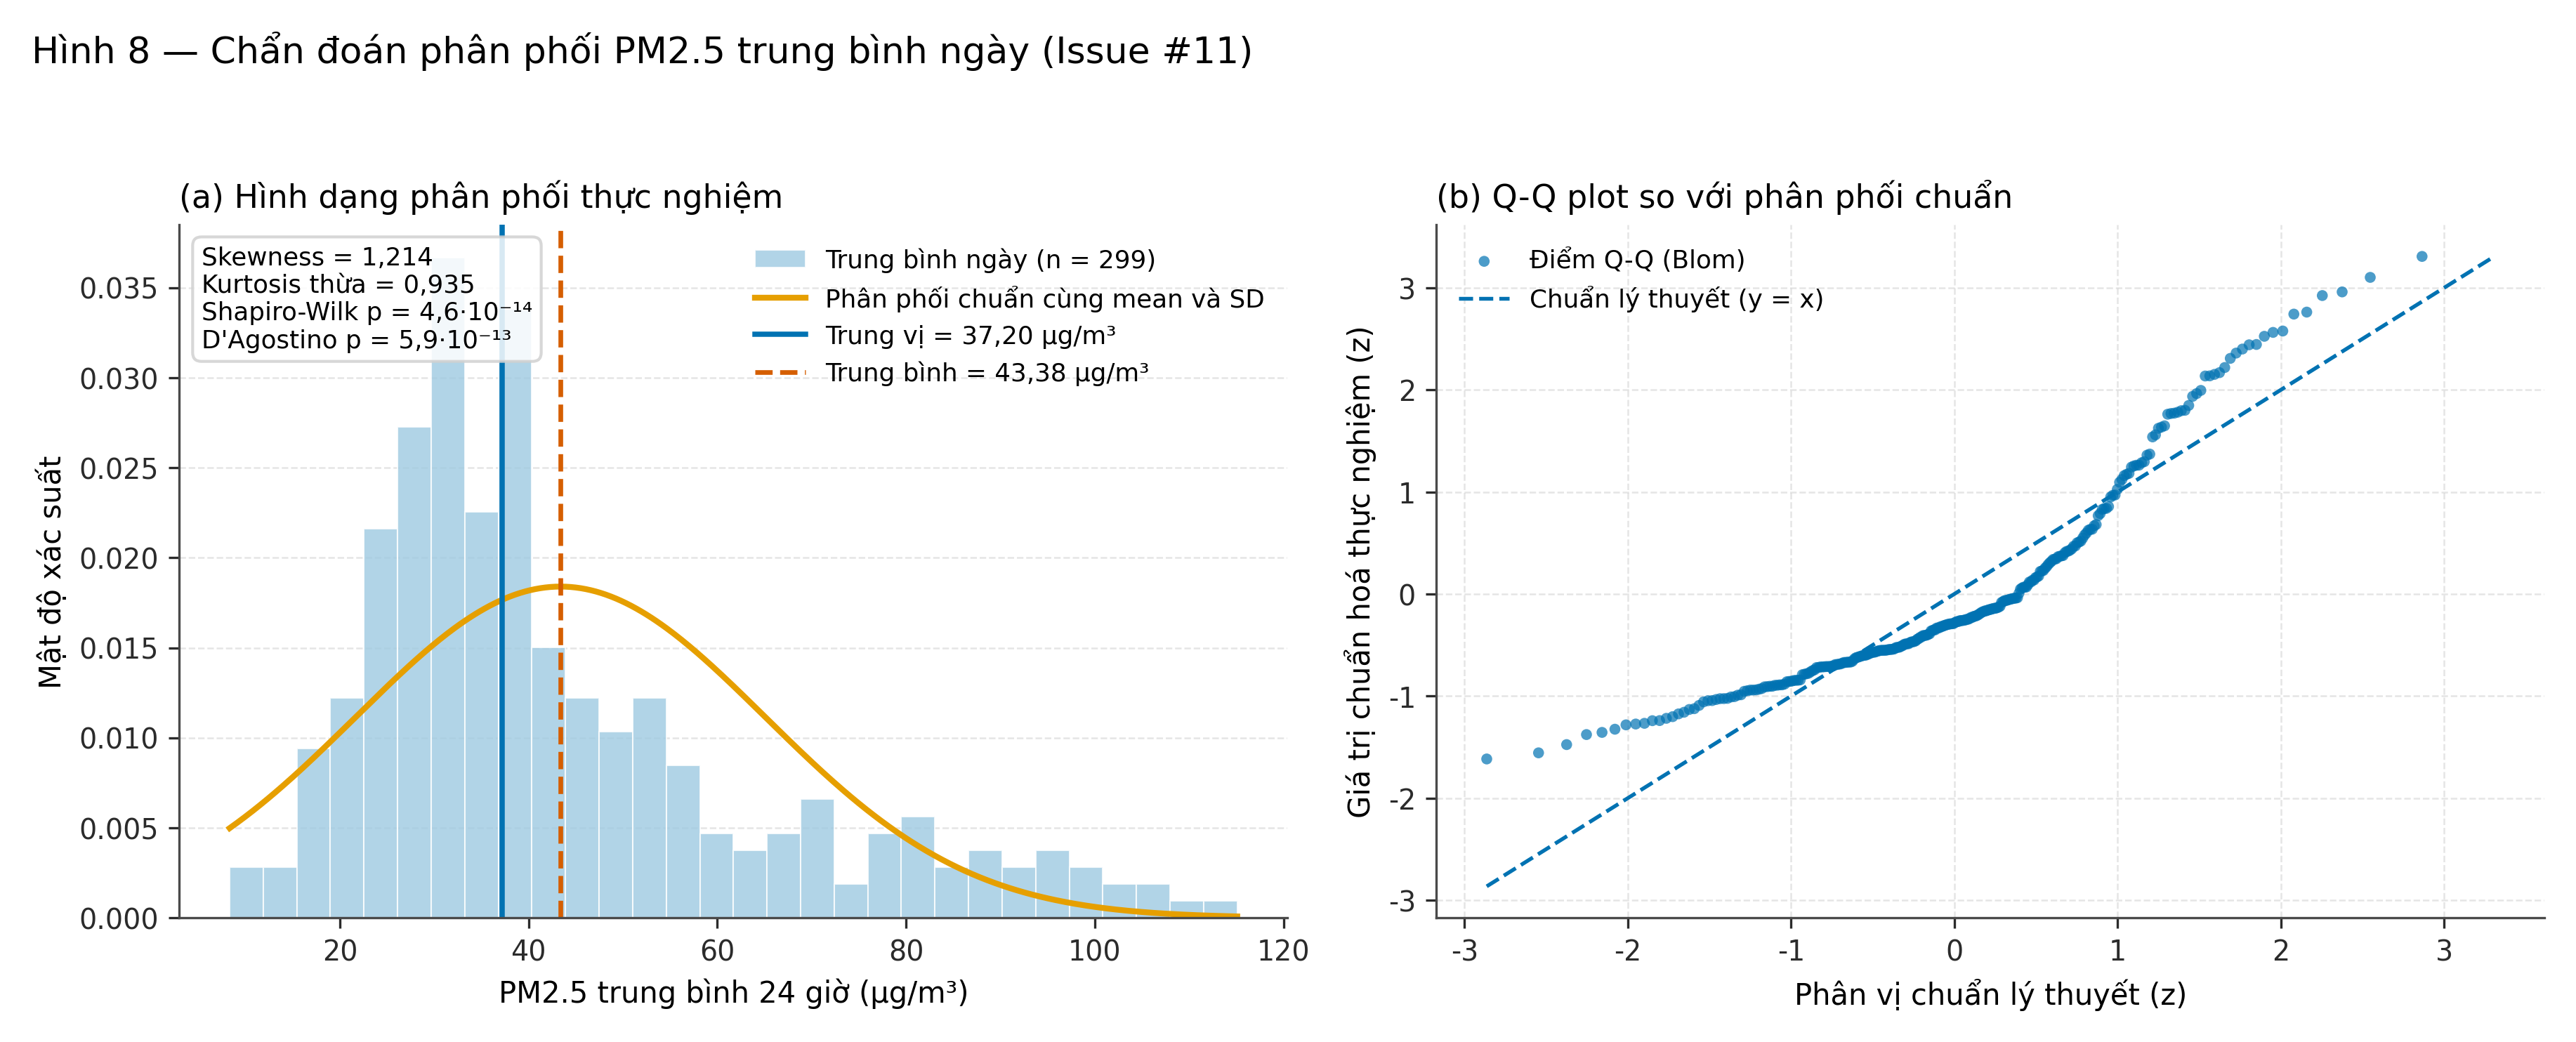

In [5]:
from IPython.display import Image, display as display_image

FIGURES = plot_inference_figures(results)
for key, filename in INFERENCE_FIGURES.items():
    path = FIGURES[key]
    assert path.exists() and path.stat().st_size > 0, path

display_image(Image(filename=str(FIGURES["distribution"]), width=760))


---

## 3. Tự tương quan và cỡ mẫu hiệu dụng — giả định nào bị vi phạm

### 3.1. Đo tự tương quan

ACF được tính trên **lưới thời gian đầy đủ**: chuỗi giờ dùng lưới giờ, chuỗi ngày
dùng lưới lịch ngày (ngày bị loại = `NaN`). Cách này quan trọng: nếu nén bỏ các
ngày thiếu rồi mới tính "lag 1", cặp giá trị đó có thể cách nhau nhiều ngày và ρ bị
chệch xuống.

### 3.2. Cỡ mẫu hiệu dụng theo xấp xỉ AR(1)

$$\hat{n}_{\text{eff}} = n \cdot \frac{1 - \hat{\rho}_1}{1 + \hat{\rho}_1}$$

Đây là **chỉ báo bậc độ lớn**, không phải hiệu chỉnh p-value. Nó trả lời: "299 ngày
này chứa bao nhiêu thông tin độc lập?" Nếu $n_{\text{eff}}$ nhỏ hơn nhiều so với
$n$, p-value của các phép kiểm giả định độc lập là **lạc quan**.

### 3.3. Cách xử lý

1. Hạ đơn vị phân tích từ **giờ** xuống **ngày**.
2. Mọi CI dùng **circular moving block bootstrap**, block **7 ngày**, **1.000 lặp**,
   seed **42**, CI percentile 95%. Không resample từng hàng giờ, cũng không resample
   độc lập từng ngày.
3. Với so sánh hai nhóm, mỗi nhóm được resample **theo block riêng** (stratified)
   để giữ nguyên cỡ mẫu từng nhóm.
4. Thêm hai **kiểm tra độ nhạy ở mức tuần** (mục 8) — nơi tự tương quan thấp hơn.


In [6]:
acf_rows = []
for lag, value in dependence["daily_acf"].items():
    acf_rows.append(("Ngày", f"lag {lag}", format_number_vi(value, 4)))
for lag, value in dependence["hourly_acf"].items():
    acf_rows.append(("Giờ", f"lag {lag}", format_number_vi(value, 4)))
display(pd.DataFrame(acf_rows, columns=["Chuỗi", "Bậc", "ACF"]))

eff = dependence["daily_effective_n"]
print(dependence["daily_series_note"])
print(f"AR(1) chuỗi ngày: ρ = {format_number_vi(eff['rho_lag1'], 4)} → "
      f"n_eff ≈ {format_number_vi(eff['n_effective'], 1)} so với n = {format_int_vi(eff['n'])} "
      f"(lạm phát ×{format_number_vi(eff['inflation_factor'], 2)}).")

assert eff["n_effective"] < eff["n"], "n_eff phải nhỏ hơn n khi ρ > 0"
assert dependence["hourly_acf"][1] > dependence["daily_acf"][1], "ACF giờ phải cao hơn ACF ngày"


,Chuỗi,Bậc,ACF
0,Ngày,lag 1,"0,7276"
1,Ngày,lag 2,"0,5484"
2,Ngày,lag 3,"0,4239"
3,Ngày,lag 7,"0,3700"
4,Ngày,lag 14,"0,3172"
5,Giờ,lag 1,"0,9403"
6,Giờ,lag 2,"0,8371"
7,Giờ,lag 3,"0,7432"
8,Giờ,lag 24,"0,5988"
9,Giờ,lag 168,"0,3449"


ACF ngày tính trên lưới lịch đầy đủ (ngày bị loại = NaN), không nén bỏ khoảng trống.
AR(1) chuỗi ngày: ρ = 0,7276 → n_eff ≈ 47,1 so với n = 299 (lạm phát ×6,34).


**Hệ quả — nói thẳng, không che.** Mann-Whitney, Kruskal-Wallis, Wilcoxon và
t-test đều giả định quan sát độc lập. Ở mức ngày, giả định đó **không** được bảo
đảm ($\hat{\rho}_1 \approx 0{,}73$), nên p-value của chúng là **lạc quan**. Block
bootstrap chỉ sửa **khoảng tin cậy**, không sửa p-value. Vì vậy:

- p được đọc là **chỉ báo độ tương thích với H₀**, không phải bằng chứng chính xác tuyệt đối.
- Mọi kết luận phải đọc kèm effect size và CI — CI mới là phần tôn trọng cấu trúc thời gian.
- Hai kiểm tra độ nhạy ở mức tuần (mục 8) tồn tại để xem kết luận có phụ thuộc vào giả định độc lập của từng ngày hay không.


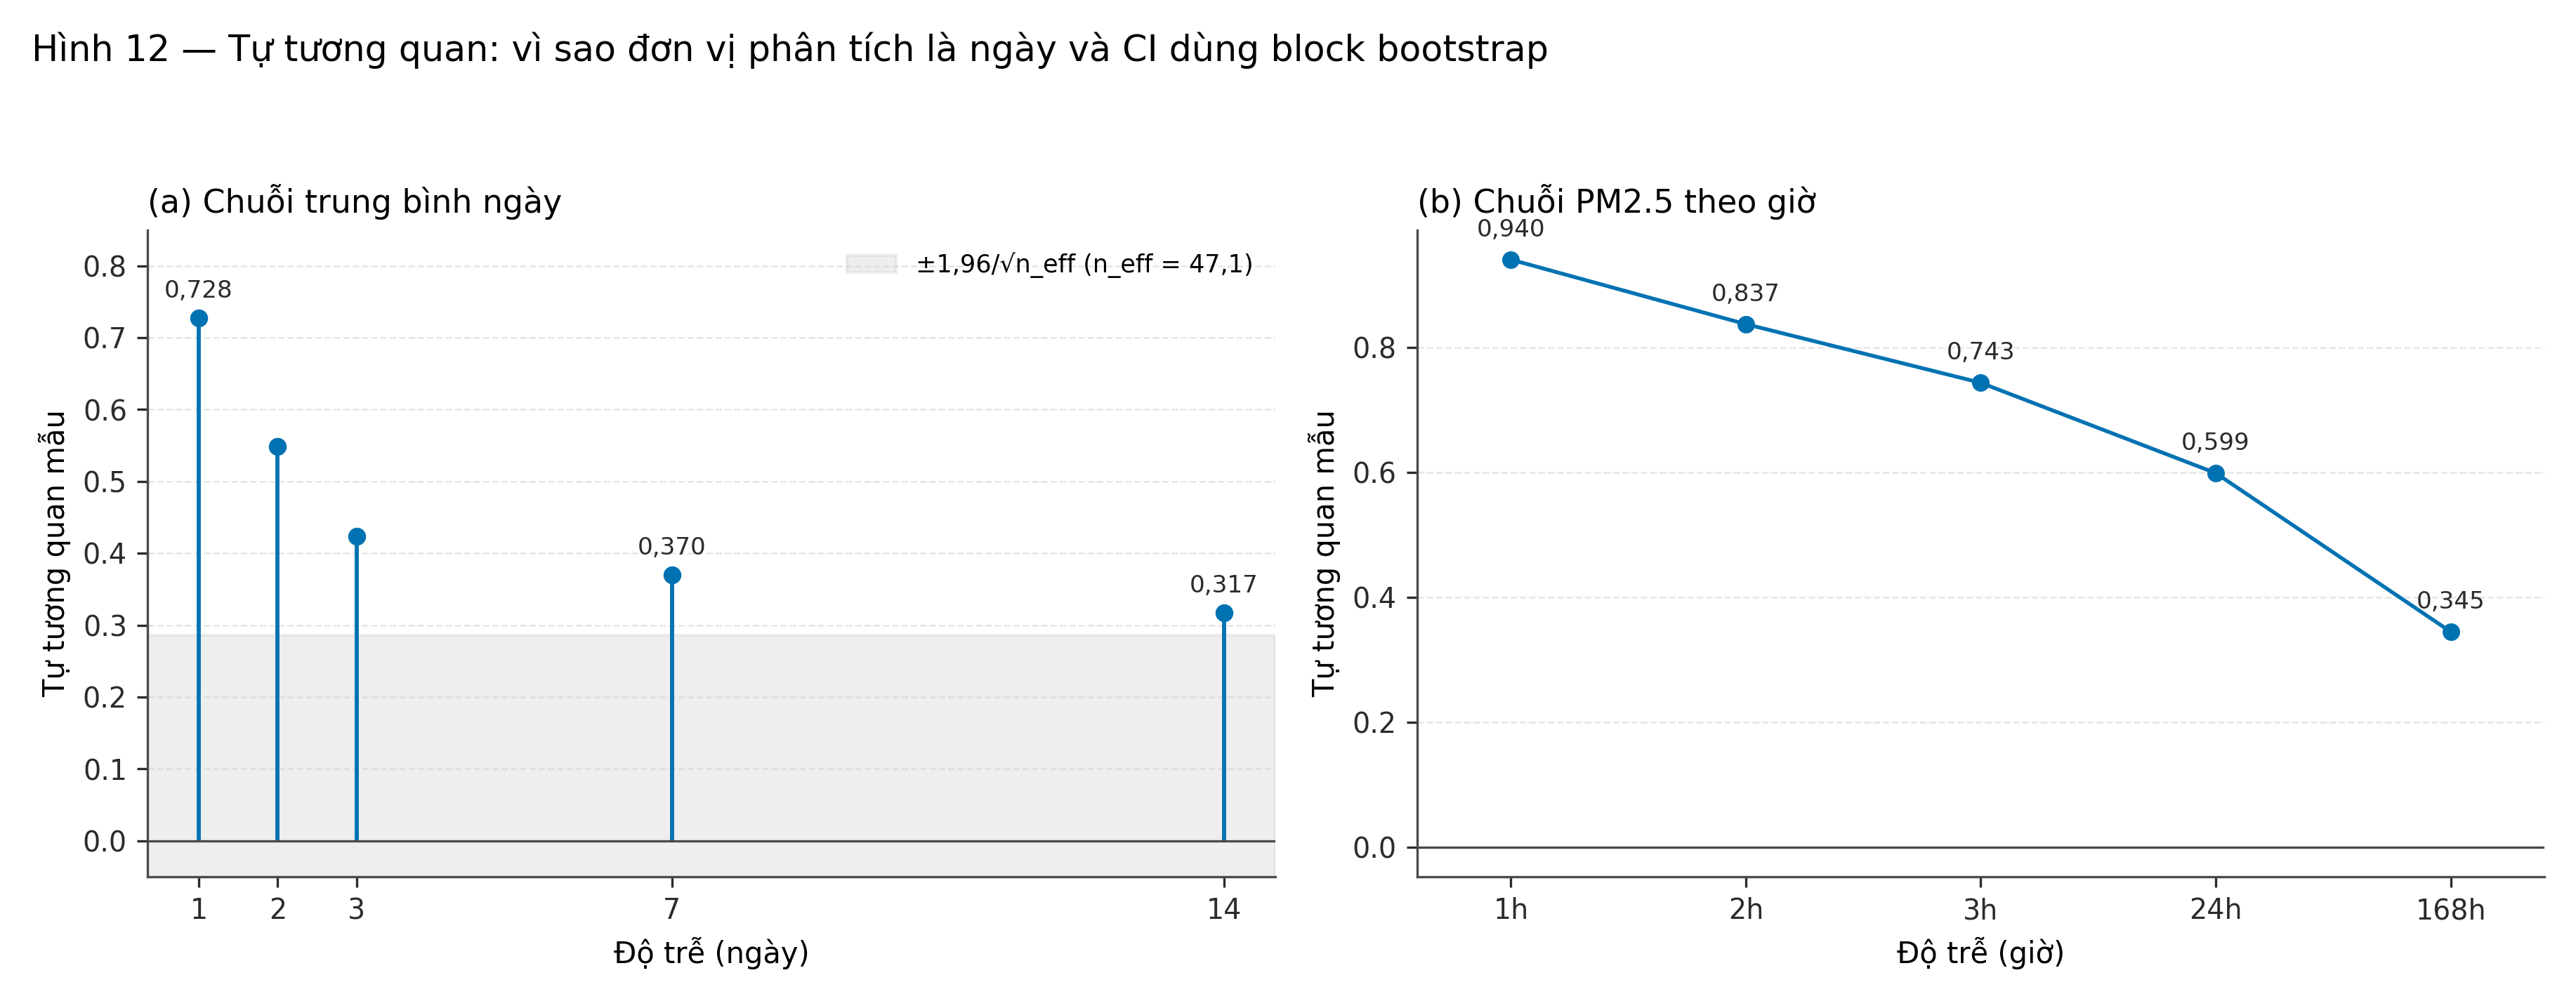

In [7]:
display_image(Image(filename=str(FIGURES["autocorrelation"]), width=760))


---

## 4. Thiết kế family xác nhận: bốn câu hỏi, bốn phép kiểm, một lần hiệu chỉnh Holm

### 4.1. Bốn giả thuyết — phát biểu trước khi xem kết quả

| # | Câu hỏi | H₀ | H₁ | Phép kiểm | Vì sao phép kiểm này |
|---|---|---|---|---|---|
| 1 | Khác biệt giữa bốn mùa | Trung vị PM₂.₅ trung bình ngày bằng nhau giữa 4 mùa | Có ít nhất một mùa khác biệt | Kruskal-Wallis | 4 nhóm (không phải 2) nên cần omnibus giữ sai lầm loại I ở α; dữ liệu lệch, có outlier |
| 2 | Ngày làm việc vs cuối tuần | Hai trung vị bằng nhau | Hai trung vị khác nhau | Mann-Whitney U | Hai nhóm độc lập về thiết kế; so hạng nên không bị vài ngày ô nhiễm nặng chi phối |
| 3 | QCVN 24 giờ (50 µg/m³) | Trung vị trung bình ngày = 50 | Trung vị ≠ 50 | Wilcoxon signed-rank một mẫu | So một chuỗi với hằng số, không giả định chuẩn; mỗi ngày là một cặp (giá trị, 50) |
| 4 | QCVN năm (25 µg/m³) | Trung bình của trung bình ngày = 25 | Trung bình ≠ 25 | t-test một mẫu | Ngưỡng năm là ngưỡng của **trung bình**, nên phép kiểm phải so trung bình |

**Cả bốn kiểm định đều hai phía, α = 0,05.** Chiều của hiệu ứng **không** được suy
từ p-value mà đọc từ ước lượng điểm và CI. Lý do: chọn một phía sau khi nhìn dữ
liệu là thay đổi giả thuyết giữa chừng — làm p mất ý nghĩa.

### 4.2. Vì sao Holm, và family gồm những gì

Holm kiểm soát FWER **không cần giả định các kiểm định độc lập** và luôn mạnh hơn
hoặc bằng Bonferroni. Family xác nhận gồm **đúng bốn** kiểm định trên — mỗi kiểm
định trả lời một câu hỏi khác nhau, hiệu chỉnh ở đây là phòng ngừa chứ không phải
để "cứu" kết luận.

Sáu cặp mùa hậu định **không** thuộc family này: chúng được khảo sát sau khi
Kruskal-Wallis bác bỏ H₀, nên mang nhãn **exploratory** và được hiệu chỉnh Holm
trong **family riêng**. Hai kiểm tra độ nhạy không nằm trong family nào.

### 4.3. Ngưỡng QCVN — đúng chu kỳ lấy mẫu

- Ngưỡng **24 giờ = 50 µg/m³** chỉ áp cho **trung bình 24 giờ**.
- Ngưỡng **năm = 25 µg/m³** chỉ áp cho **trung bình năm**.

Không có phép so sánh nào giữa **một giờ** với ngưỡng ngày/năm. Báo cáo cũng
**không** kết luận "đạt/không đạt QCVN": quy chuẩn có quy tắc đánh giá tuân thủ
riêng (số ngày vượt được phép trong năm) mà dự án không mã hoá.


In [8]:
design_rows = []
for row in holm_table:
    test = tests[row["key"]]
    if row["key"] == "season_kruskal":
        n_text = f"n = {format_int_vi(test['n'])} ngày / 4 nhóm"
    elif row["key"] == "weekday_mannwhitney":
        n_text = f"n₁ = {format_int_vi(test['n_a'])}, n₂ = {format_int_vi(test['n_b'])}"
    else:
        n_text = f"n = {format_int_vi(test['n'])} ngày"
    design_rows.append((row["label"], n_text, test["alternative"], test["statistic_name"]))

display(pd.DataFrame(design_rows, columns=["Kiểm định", "Cỡ mẫu", "Alternative", "Thống kê"]))
print(f"→ Tổng số quan sát bị loại khỏi panel: {format_int_vi(audit['days_dropped'])} ngày "
      f"(từ {format_int_vi(audit['days_with_any_observation'])} ngày có quan sát).")


,Kiểm định,Cỡ mẫu,Alternative,Thống kê
0,"Mùa (Kruskal-Wallis, 4 nhóm)",n = 299 ngày / 4 nhóm,two-sided (omnibus),H
1,Ngày làm việc vs cuối tuần (Mann-Whitney),"n₁ = 213, n₂ = 86",two-sided,U
2,Trung bình 24h vs 50 µg/m³ (Wilcoxon),n = 299 ngày,two-sided,W
3,Trung bình giai đoạn vs 25 µg/m³ (t một mẫu),n = 299 ngày,two-sided,t


→ Tổng số quan sát bị loại khỏi panel: 52 ngày (từ 351 ngày có quan sát).


### 4.4. Kết quả family xác nhận — p thô và p Holm cạnh nhau

Cột **p thô** được giữ nguyên để người đọc tự kiểm tra: hiệu chỉnh Holm có làm đổi
kết luận hay không. Với bốn kiểm định này, không có kết luận nào đổi chiều.


In [9]:
holm_rows = []
for row in holm_table:
    test = tests[row["key"]]
    holm_rows.append({
        "Kiểm định": row["label"],
        "Thống kê": f"{row['statistic_name']} = {format_number_vi(row['statistic'], 4)}",
        "p thô": p_text(row["p_raw"]),
        "p Holm": p_text(row["p_holm"]),
        "Effect size": f"{row['effect_size_name']} = {format_number_vi(row['effect_size'], 4)}",
        "Kết luận (Holm)": "bác bỏ H₀" if row["reject_holm"] else "không bác bỏ H₀",
    })
display(pd.DataFrame(holm_rows))

for row in holm_table:
    assert row["p_holm"] >= row["p_raw"] - 1e-12, "Holm không được làm p nhỏ đi"
    assert row["reject_holm"] == (row["p_holm"] < ALPHA)
    assert row["reject_raw"] == (row["p_raw"] < ALPHA)

n_reject = sum(row["reject_holm"] for row in holm_table)
print(f"→ {n_reject}/4 kiểm định bác bỏ H₀ sau hiệu chỉnh Holm ở α = {ALPHA}.")


,Kiểm định,Thống kê,p thô,p Holm,Effect size,Kết luận (Holm)
0,"Mùa (Kruskal-Wallis, 4 nhóm)","H = 61,5344","2,76·10⁻¹³","8,29·10⁻¹³","epsilon_squared = 0,2065",bác bỏ H₀
1,Ngày làm việc vs cuối tuần (Mann-Whitney),"U = 8083,0000","0,1120","0,1120","r_rb = −0,1175",không bác bỏ H₀
2,Trung bình 24h vs 50 µg/m³ (Wilcoxon),"W = 13227,0000","7,88·10⁻¹⁰","1,58·10⁻⁹","r_rb_pairs = −0,4102",bác bỏ H₀
3,Trung bình giai đoạn vs 25 µg/m³ (t một mẫu),"t = 14,6563","5,33·10⁻³⁷","2,13·10⁻³⁶","cohen_d = 0,8476",bác bỏ H₀


→ 3/4 kiểm định bác bỏ H₀ sau hiệu chỉnh Holm ở α = 0.05.


---

## 5. Kiểm định 1 — Khác biệt giữa bốn mùa (Kruskal-Wallis)

**H₀:** trung vị PM₂.₅ trung bình ngày bằng nhau giữa bốn mùa.  
**H₁:** có ít nhất một mùa có trung vị khác.  
**α = 0,05, hai phía.**

### 5.1. Vì sao Kruskal-Wallis

- **Bốn nhóm**, không phải hai: dùng một loạt Mann-Whitney cho 6 cặp sẽ thổi phồng sai lầm loại I; KW omnibus giữ mức α trước, rồi mới khảo sát cặp.
- Phân phối lệch phải và có outlier (mục 2) → so sánh hạng ổn định hơn ANOVA trên trung bình.
- Effect size dùng $\varepsilon^2 = H/(n-1)$ — tỷ lệ phương sai **hạng** giải thích bởi mùa.

### 5.2. Vì sao mùa được định nghĩa theo khí tượng

Đông = 12–2, Xuân = 3–5, Hè = 6–8, Thu = 9–11. Định nghĩa này cố định trong
`src/flag_evidence.py` và dùng chung với Issue #8, nên nhãn mùa của hai notebook
không thể lệch nhau.


In [10]:
season = tests["season_kruskal"]
season_rows = [
    (SEASON_LABELS_VI[s], format_int_vi(season["group_sizes"][s]), format_number_vi(season["group_medians"][s]))
    for s in SEASON_DISPLAY_ORDER if s in season["group_sizes"]
]
display(pd.DataFrame(season_rows, columns=["Mùa", "n (ngày)", "Trung vị (µg/m³)"]))

season_ci = season["ci_dong_vs_he"]
print(f"H = {format_number_vi(season['statistic'], 4)} · df = {season['df']} · "
      f"n = {format_int_vi(season['n'])}")
print(f"p thô  = {p_text(season['p_value'])}")
print(f"p Holm = {p_text(season['p_holm'])}")
print(f"ε²     = {format_number_vi(season['effect_size'], 4)}")
print(f"CI 95% block bootstrap cho trung vị Đông − Hè: "
      f"{format_number_vi(season_ci['point'])} µg/m³, {ci_text(season_ci)}")

assert season["p_holm"] < ALPHA
assert 0.0 <= season["effect_size"] <= 1.0
assert season_ci["point"] > 0 and season_ci["ci_low"] > 0, "CI không chứa 0 → khác biệt dương rõ"


,Mùa,n (ngày),Trung vị (µg/m³)
0,Đông,79,"60,46"
1,Xuân,83,"32,81"
2,Hè,53,"31,14"
3,Thu,84,"36,30"


H = 61,5344 · df = 3 · n = 299
p thô  = 2,76·10⁻¹³
p Holm = 8,29·10⁻¹³
ε²     = 0,2065
CI 95% block bootstrap cho trung vị Đông − Hè: 29,32 µg/m³, [9,93; 42,75]


**Đọc kết quả.** Khác biệt mùa có ý nghĩa thống kê **và** có ý nghĩa thực tiễn:
$\varepsilon^2$ ở mức trung bình–lớn theo quy ước Cohen, và CI của chênh lệch Đông −
Hè không chứa 0. Đây là kết luận **mô tả cho giai đoạn 07/2025–07/2026**, không
ngoại suy sang năm khác hay trạm khác (mục 12).

### 5.3. Hậu định sáu cặp mùa — exploratory, Holm family riêng

Sáu cặp dưới đây **không** tham gia family xác nhận. Chúng chỉ định vị khác biệt
nằm ở đâu; kết luận của Issue #11 vẫn dựa vào KW omnibus ở trên.


In [11]:
pair_rows = []
for pair in posthoc["pairs"]:
    pair_rows.append({
        "Cặp": pair["pair"],
        "Trung vị A": format_number_vi(pair["median_a"]),
        "Trung vị B": format_number_vi(pair["median_b"]),
        "U": format_number_vi(pair["statistic"], 1),
        "p thô": p_text(pair["p_value"]),
        "p Holm": p_text(pair["p_holm"]),
        "r_rb": format_number_vi(pair["effect_size"], 3),
        "CI 95% (A−B)": ci_text(pair["ci"]),
        "Kết luận": "bác bỏ H₀" if pair["reject_holm"] else "không bác bỏ H₀",
    })
display(pd.DataFrame(pair_rows))
assert posthoc["n_pairs"] == 6
assert all(p["p_holm"] >= p["p_value"] - 1e-12 for p in posthoc["pairs"])
print("→ Family hậu định: 6 cặp, Holm riêng, nhãn exploratory.")


,Cặp,Trung vị A,Trung vị B,U,p thô,p Holm,r_rb,CI 95% (A−B),Kết luận
0,Đông – Xuân,"60,46","32,81","5191,0","1,49·10⁻¹⁰","7,44·10⁻¹⁰","0,583","[7,77; 41,48]",bác bỏ H₀
1,Đông – Hè,"60,46","31,14","3519,0","3,72·10⁻¹¹","2,23·10⁻¹⁰","0,681","[9,93; 42,75]",bác bỏ H₀
2,Đông – Thu,"60,46","36,30","4951,0","5,93·10⁻⁸","2,37·10⁻⁷","0,492","[5,06; 38,89]",bác bỏ H₀
3,Xuân – Hè,"32,81","31,14","2512,0","0,1639","0,3277","0,142","[−4,11; 8,44]",không bác bỏ H₀
4,Xuân – Thu,"32,81","36,30","3140,0","0,2688","0,3277","−0,099","[−9,09; 4,53]",không bác bỏ H₀
5,Hè – Thu,"31,14","36,30","1731,0","0,0289","0,0866","−0,222","[−10,19; 0,85]",không bác bỏ H₀


→ Family hậu định: 6 cặp, Holm riêng, nhãn exploratory.


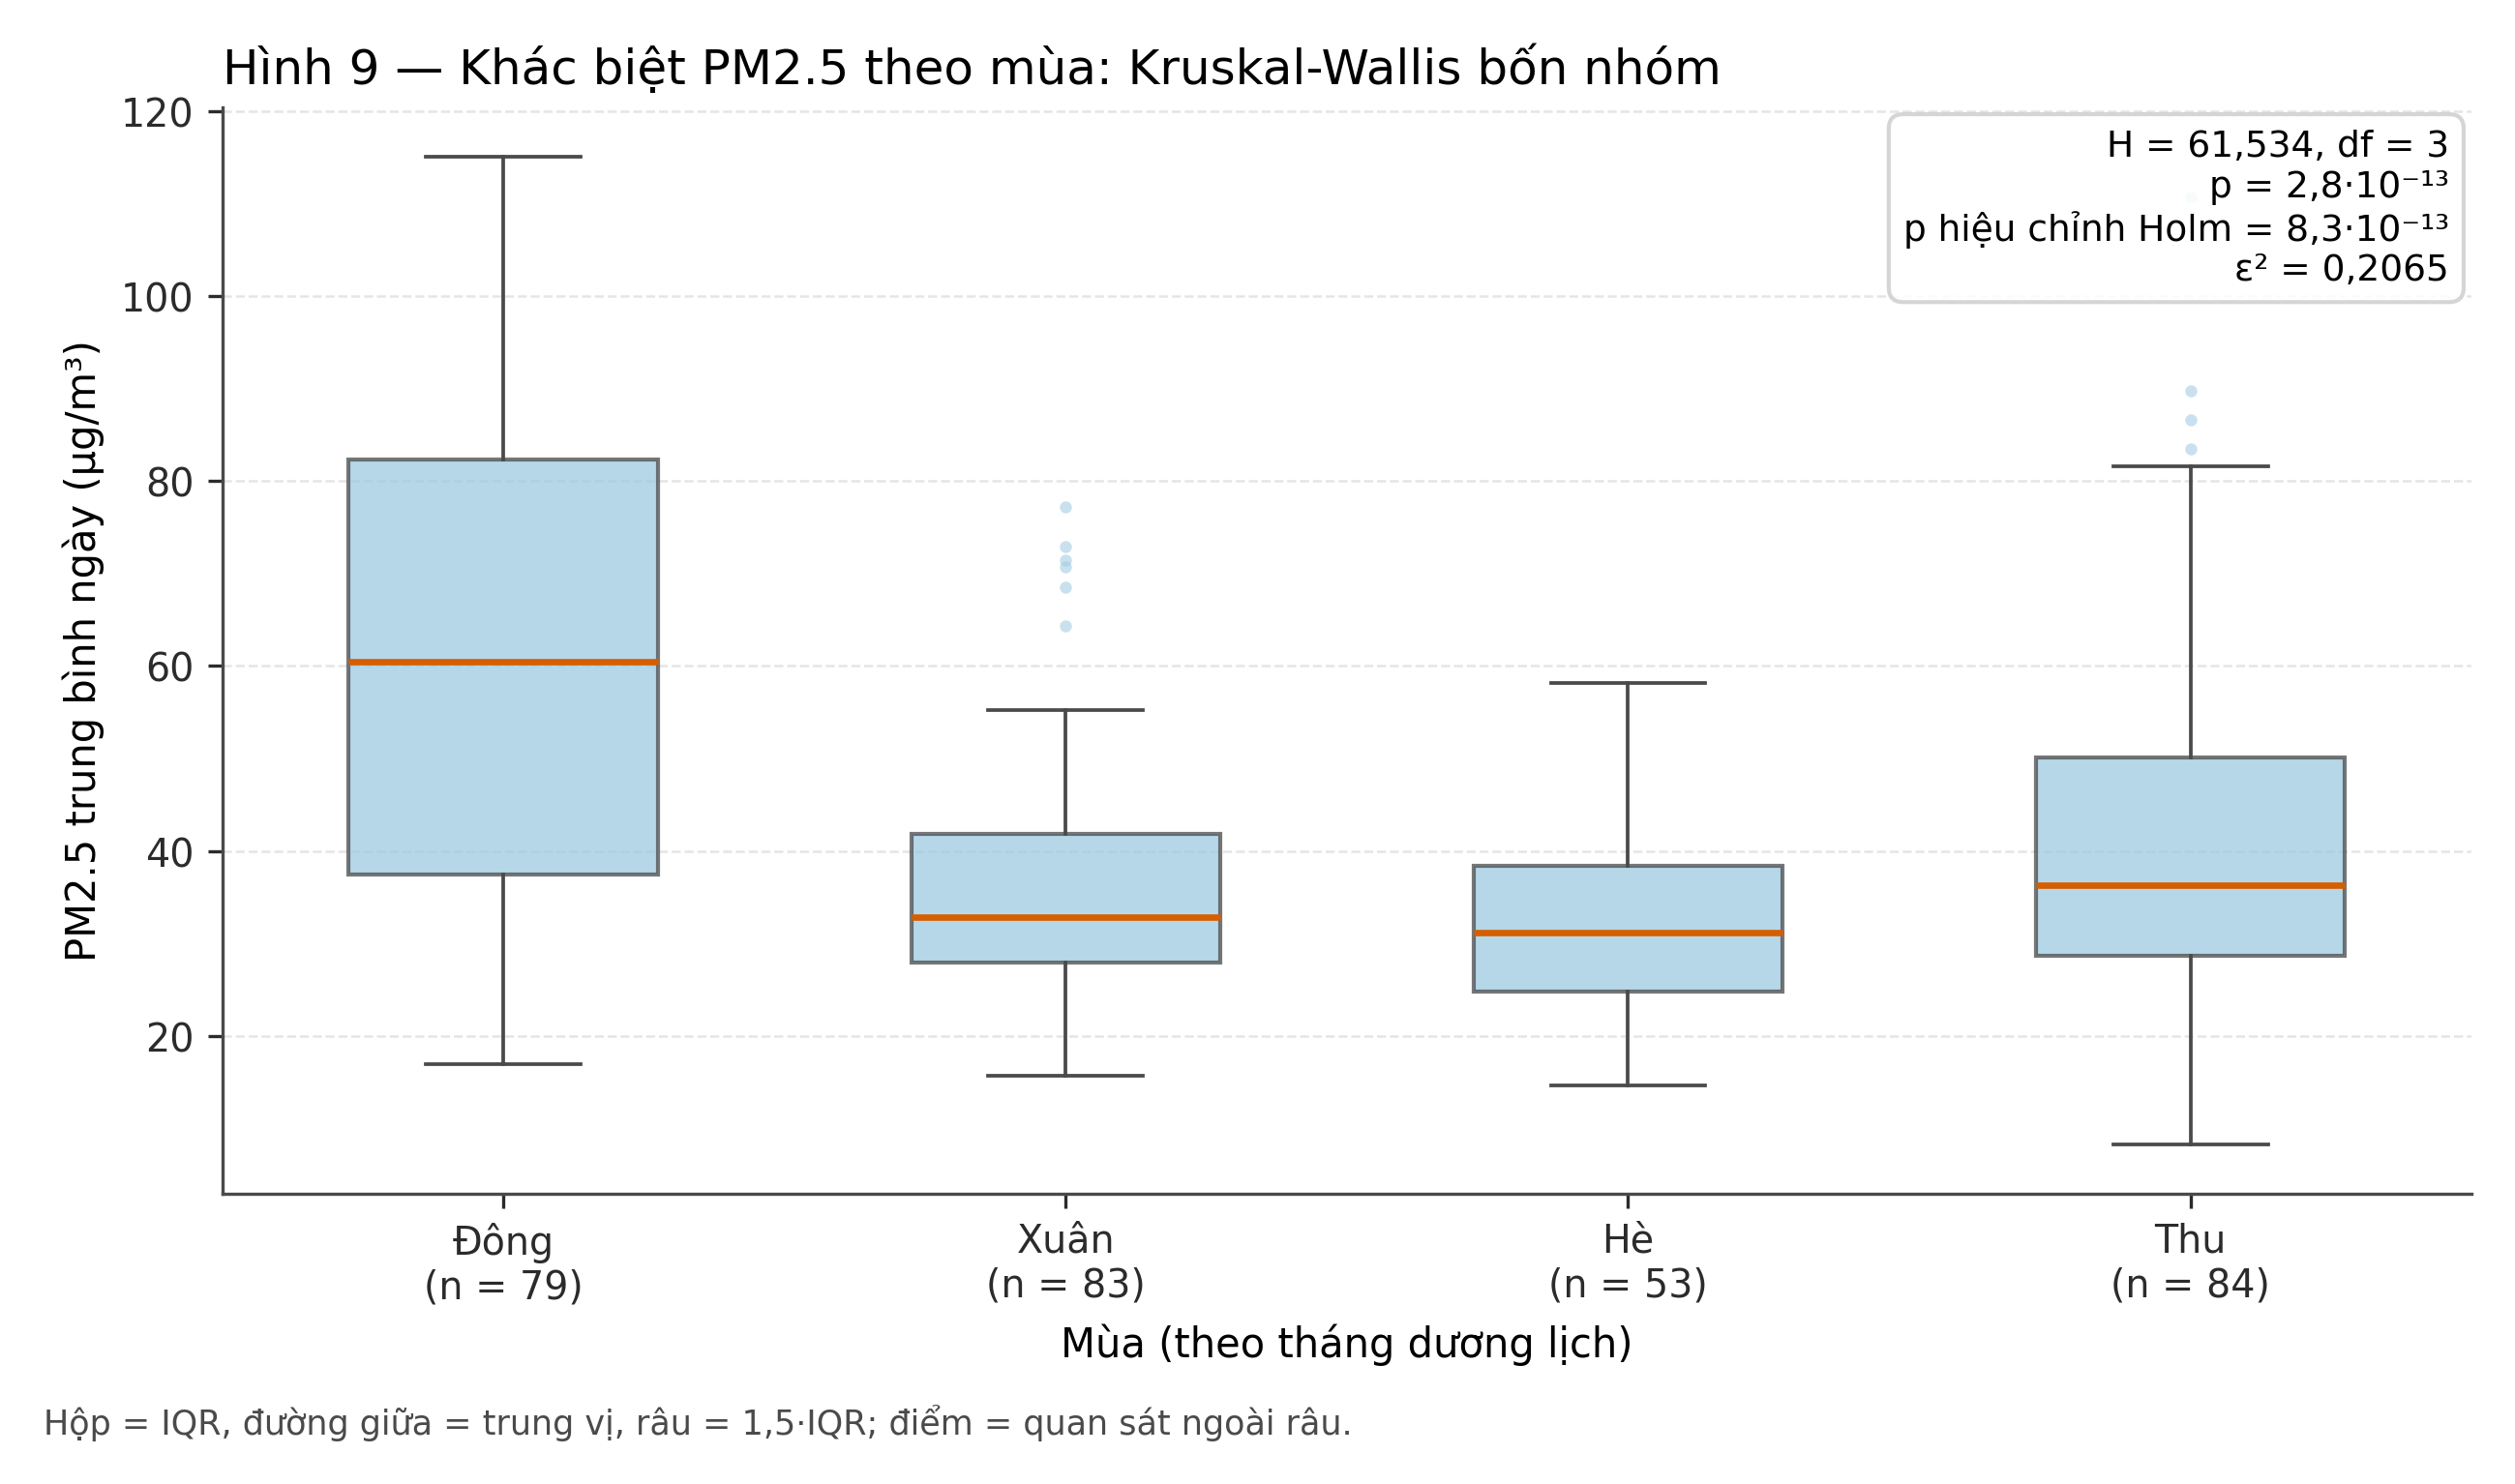

In [12]:
display_image(Image(filename=str(FIGURES["season"]), width=760))


---

## 6. Kiểm định 2 — Ngày làm việc vs ngày cuối tuần (Mann-Whitney U)

**H₀:** trung vị PM₂.₅ trung bình ngày của ngày làm việc bằng của ngày cuối tuần.  
**H₁:** hai trung vị khác nhau.  
**α = 0,05, hai phía.**

### 6.1. Vì sao Mann-Whitney

Hai nhóm **độc lập về thiết kế** (một ngày chỉ thuộc đúng một nhóm), nhưng phân
phối lệch và có outlier. MW so sánh hạng nên không bị vài ngày ô nhiễm nặng chi
phối. Effect size $r_{rb} = 2U/(n_1 n_2) - 1$, quy ước **dương = ngày làm việc cao
hơn** — quy ước này được ghi ngay trong module để không ai đảo dấu.

### 6.2. "Không bác bỏ H₀" không có nghĩa "hai nhóm bằng nhau"

Đây là chỗ dễ đọc sai nhất. Báo cáo kèm **MDE** — chênh lệch nhỏ nhất phát hiện
được ở power 80%, α = 0,05, tính hậu nghiệm từ SD quan sát:

$$\text{MDE} = (z_{1-\alpha/2} + z_{\text{power}}) \cdot s_{\text{pooled}} \cdot \sqrt{\tfrac{1}{n_1} + \tfrac{1}{n_2}}$$

MDE là **ngưỡng phân giải của phép kiểm**, không phải kết luận về hiệu ứng. Nếu
chênh lệch quan sát nhỏ hơn MDE thì dữ liệu **không đủ độ phân giải** để tách "không
có khác biệt" khỏi "khác biệt nhỏ hơn MDE".


In [13]:
weekday = tests["weekday_mannwhitney"]
mde = sensitivity["power_mde"]
weekday_ci = weekday["ci"]

print(f"Ngày làm việc: n = {format_int_vi(weekday['n_a'])}, trung vị {format_number_vi(weekday['median_a'])} µg/m³")
print(f"Ngày cuối tuần: n = {format_int_vi(weekday['n_b'])}, trung vị {format_number_vi(weekday['median_b'])} µg/m³")
print(f"U = {format_number_vi(weekday['statistic'], 1)} · p thô = {p_text(weekday['p_value'])} · "
      f"p Holm = {p_text(weekday['p_holm'])}")
print(f"Chênh lệch trung vị (weekday − weekend) = {format_number_vi(weekday['median_difference'])} µg/m³, "
      f"CI 95% {ci_text(weekday_ci)}")
print(f"r_rb = {format_number_vi(weekday['effect_size'], 4)}  (dương = ngày làm việc cao hơn)")
print(f"MDE ≈ {format_number_vi(mde['mde'])} µg/m³ "
      f"(SD gộp {format_number_vi(mde['pooled_sd'])}; power {mde['power']:.0%}; α = {mde['alpha']})")

ci_includes_zero = weekday_ci["ci_low"] <= 0.0 <= weekday_ci["ci_high"]
print(f"CI chứa 0: {ci_includes_zero} · |chênh lệch| < MDE: {abs(weekday['median_difference']) < mde['mde']}")
assert weekday["p_holm"] >= ALPHA
assert ci_includes_zero
assert abs(weekday["median_difference"]) < mde["mde"]


Ngày làm việc: n = 213, trung vị 36,72 µg/m³
Ngày cuối tuần: n = 86, trung vị 39,45 µg/m³
U = 8083,0 · p thô = 0,1120 · p Holm = 0,1120
Chênh lệch trung vị (weekday − weekend) = −2,74 µg/m³, CI 95% [−15,01; 4,19]
r_rb = −0,1175  (dương = ngày làm việc cao hơn)
MDE ≈ 7,75 µg/m³ (SD gộp 21,65; power 80%; α = 0.05)
CI chứa 0: True · |chênh lệch| < MDE: True


**Đọc kết quả.** Không bác bỏ H₀. Nhưng vì chênh lệch quan sát **nhỏ hơn MDE** và
CI chứa 0, kết luận đúng là: *dữ liệu không đủ độ phân giải để kết luận có hay không
một khác biệt nhỏ hơn MDE* — **không** phải "ngày làm việc và cuối tuần bằng nhau".
Ước lượng điểm còn nằm trong khoảng sai số thực hành của một trạm đo, nên không
được dùng để quy kết nguồn phát thải hay hành vi giao thông.


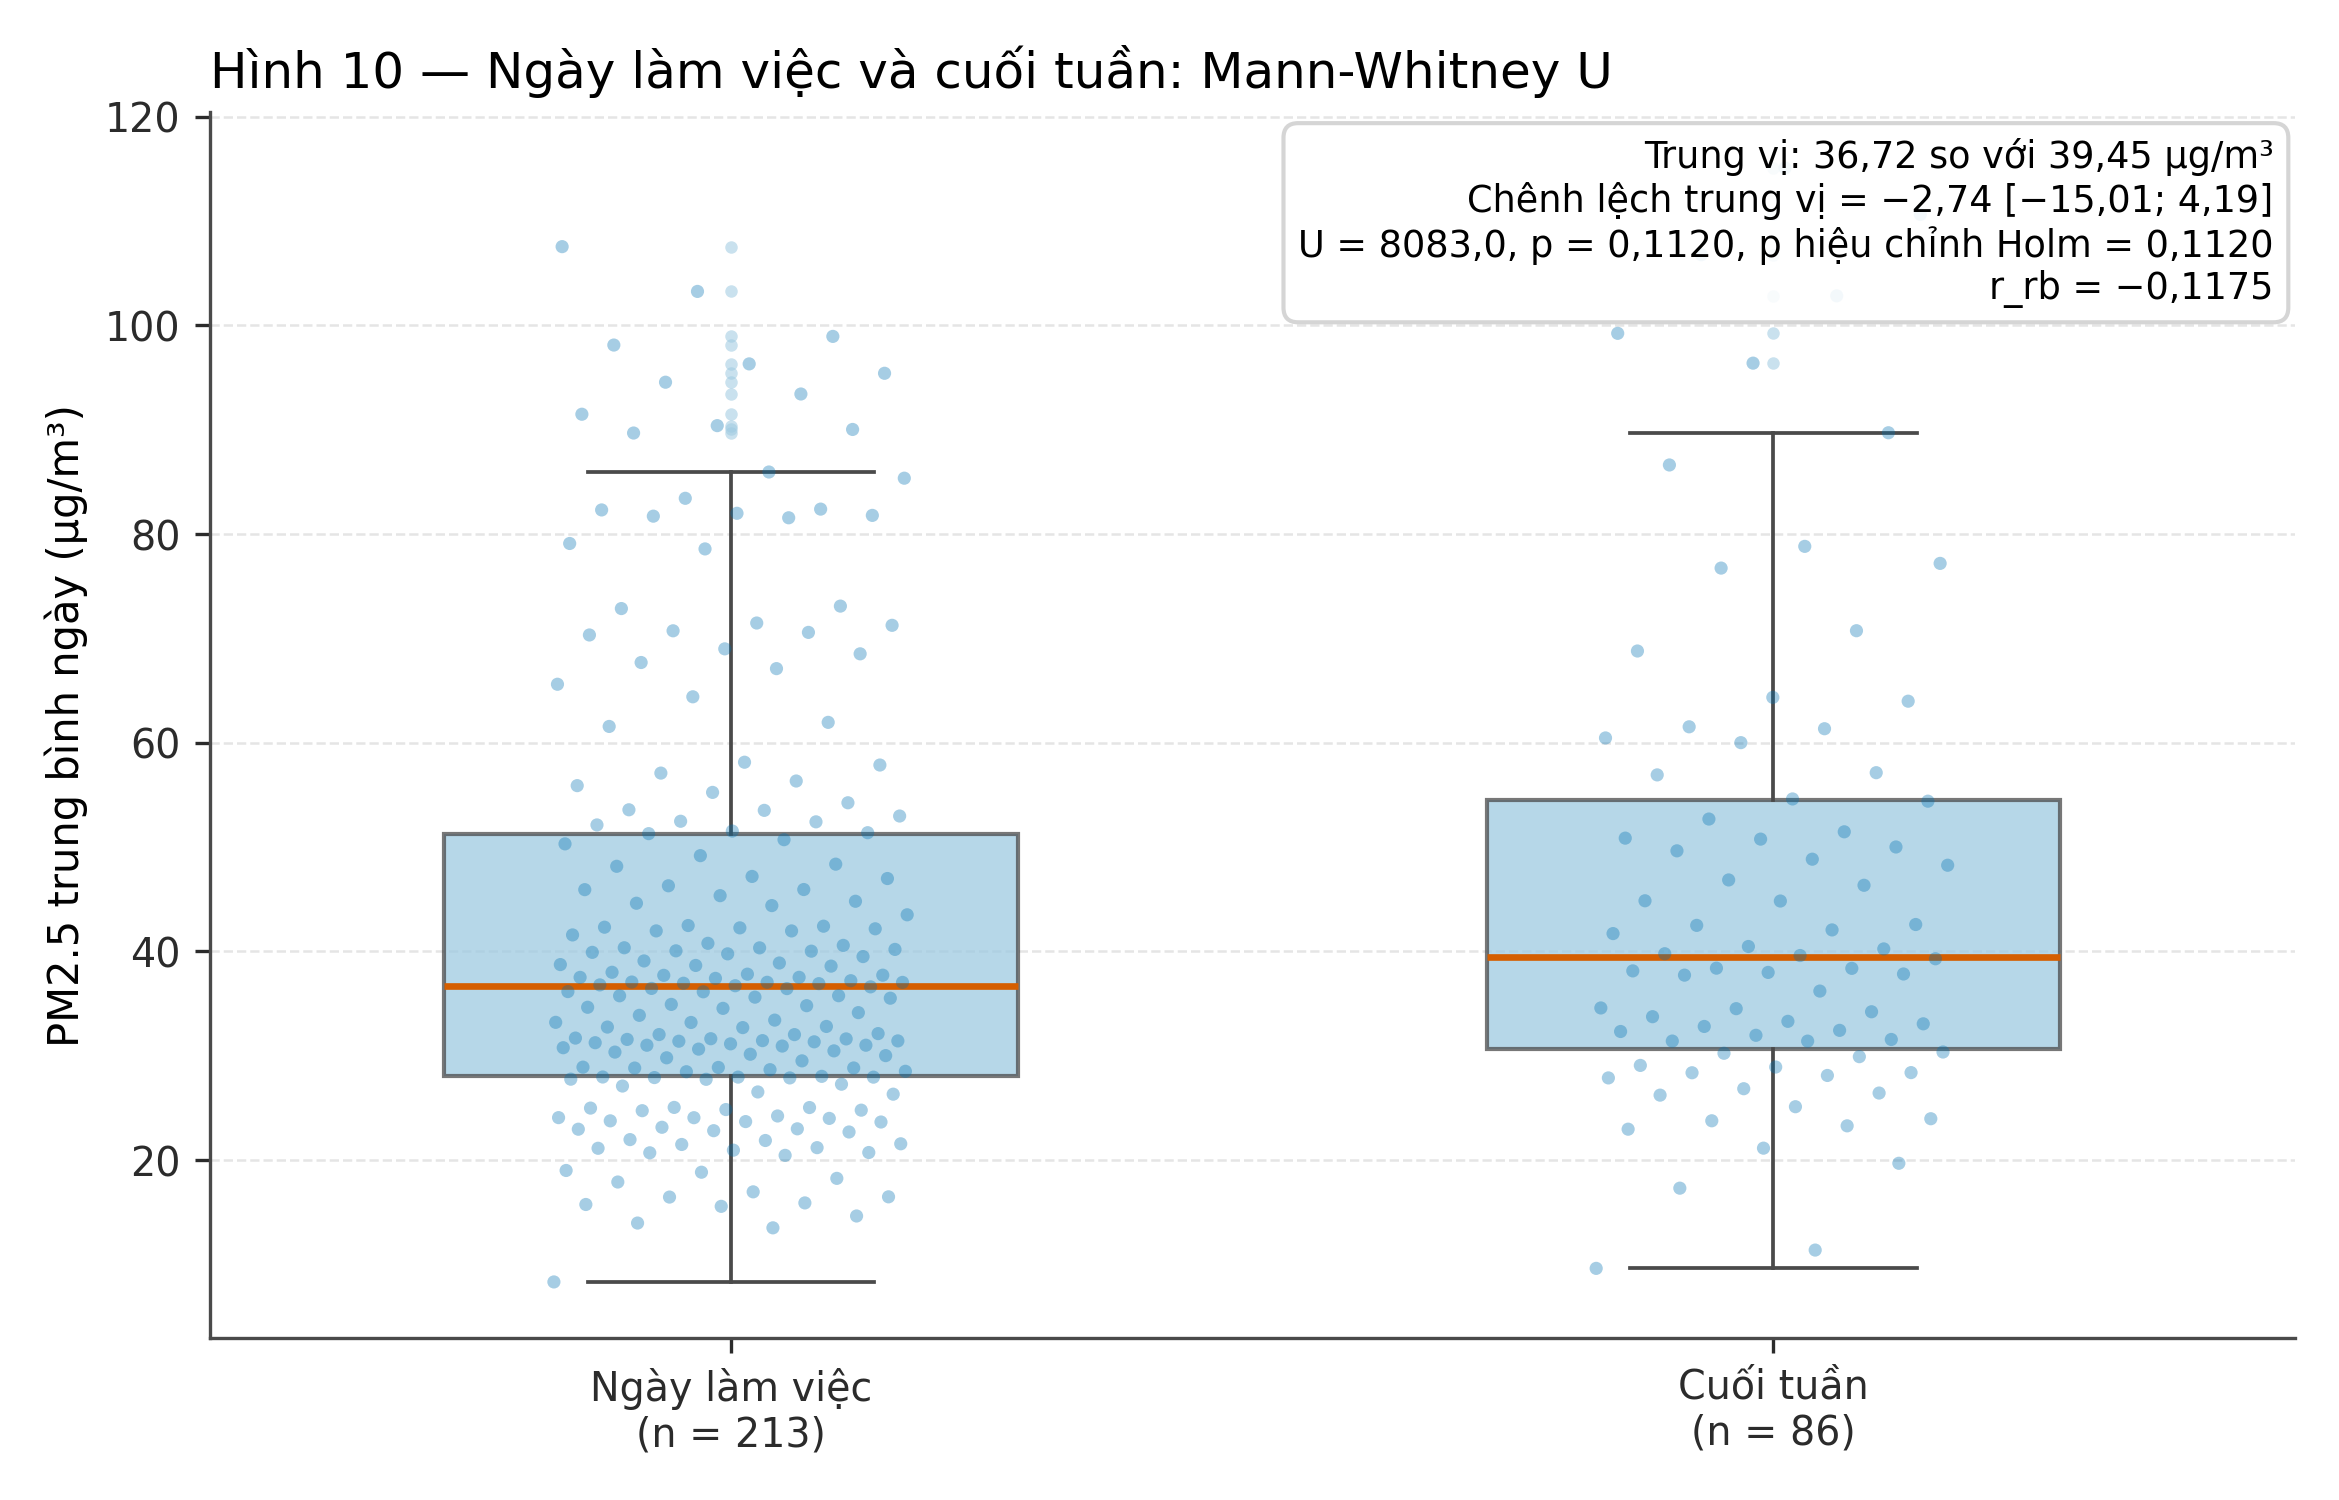

In [14]:
display_image(Image(filename=str(FIGURES["weekday"]), width=760))


---

## 7. Kiểm định 3 — Đối chiếu QCVN 05:2023/BTNMT, đúng chu kỳ lấy mẫu

Hai ngưỡng được kiểm định **tách biệt**, mỗi ngưỡng đi với đúng chu kỳ trung bình
của nó:

| Ngưỡng | Giá trị | Đơn vị áp dụng | Phép kiểm | Tham số so sánh |
|---|---|---|---|---|
| Trung bình **24 giờ** | 50 µg/m³ | Trung bình của 24 giờ | Wilcoxon signed-rank | **Trung vị** của trung bình ngày |
| Trung bình **năm** | 25 µg/m³ | Trung bình của một năm | t-test một mẫu | **Trung bình** của trung bình ngày |

Không có phép so sánh nào giữa **một giờ** với ngưỡng ngày hoặc ngưỡng năm.

### 7.1. Ngưỡng 24 giờ — 50 µg/m³

**H₀:** trung vị của trung bình ngày bằng 50 µg/m³.  
**H₁:** trung vị khác 50.  
**α = 0,05, hai phía.**

Vì sao Wilcoxon signed-rank: so một chuỗi với một hằng số, không giả định chuẩn;
mỗi ngày là một cặp (giá trị, 50). Effect size $r = (W^+ - W^-)/(W^+ + W^-)$,
**âm = trung vị nằm dưới ngưỡng**.

### 7.2. Ngưỡng năm — 25 µg/m³

**H₀:** trung bình của trung bình ngày bằng 25 µg/m³.  
**H₁:** trung bình khác 25.  
**α = 0,05, hai phía.**

Vì sao t-test một mẫu: ngưỡng năm là ngưỡng của **trung bình**, nên phép kiểm phải
so trung bình — dùng trung vị ở đây sẽ trả lời một câu hỏi khác.

> **Giới hạn thiết kế:** dải dữ liệu 07/2025–07/2026 **không** trùng năm dương lịch.
> Đại lượng được kiểm định là trung bình **giai đoạn quan sát**, không phải "trung
> bình năm" theo định nghĩa quy chuẩn. Nó là chỉ báo mức nền, không phải phán quyết
> tuân thủ.

### 7.3. Hai mẫu số, hai câu hỏi — không được trộn

| Cách đếm | Tử số | Mẫu số | Trả lời câu hỏi |
|---|---|---|---|
| Cửa sổ trượt 24 giờ | Số cửa sổ ≥ 50 | Số cửa sổ hợp lệ | "Bao nhiêu phần trăm **cửa sổ 24 giờ** vượt ngưỡng?" |
| Trung bình ngày | Số ngày ≥ 50 | Số ngày đủ độ phủ | "Bao nhiêu phần trăm **ngày** vượt ngưỡng?" |

Ghép tử số của cách này với mẫu số của cách kia sẽ cho một tỷ lệ **không ứng với
đơn vị nào**. Ví dụ cụ thể được in ở cell dưới.


In [15]:
q24 = tests["qcvn_24h_wilcoxon"]
annual = tests["qcvn_annual_ttest"]

print(f"[24 giờ] n = {format_int_vi(q24['n'])} ngày · trung vị {format_number_vi(q24['median'])} µg/m³")
print(f"  W = {format_number_vi(q24['statistic'], 1)} "
      f"(W⁺ = {format_number_vi(q24['w_plus'], 1)}, W⁻ = {format_number_vi(q24['w_minus'], 1)})")
print(f"  p thô = {p_text(q24['p_value'])} · p Holm = {p_text(q24['p_holm'])}")
print(f"  r = {format_number_vi(q24['effect_size'], 4)} (âm = dưới ngưỡng)")
print(f"  CI 95% block bootstrap cho trung vị: {ci_text(q24['ci_bootstrap'])}")

print()
print(f"[Năm] n = {format_int_vi(annual['n'])} ngày · trung bình {format_number_vi(annual['mean'])} "
      f"± {format_number_vi(annual['sd'])} µg/m³")
print(f"  t = {format_number_vi(annual['statistic'], 4)} · df = {annual['df']}")
print(f"  p thô = {p_text(annual['p_value'])} · p Holm = {p_text(annual['p_holm'])}")
print(f"  Cohen's d = {format_number_vi(annual['effect_size'], 4)}")
print(f"  CI 95% theo t (giả định độc lập): {ci_text(annual['ci_t'])}")
print(f"  CI 95% block bootstrap (tôn trọng tự tương quan): {ci_text(annual['ci_bootstrap'])}")

assert q24["mu"] == QCVN_2023_PM25_24H_LIMIT == 50.0
assert annual["mu"] == QCVN_2023_PM25_ANNUAL_LIMIT == 25.0
assert q24["p_holm"] < ALPHA and annual["p_holm"] < ALPHA
assert q24["median"] < QCVN_2023_PM25_24H_LIMIT
assert annual["mean"] > QCVN_2023_PM25_ANNUAL_LIMIT

# Hai CI của phép kiểm trung bình phải khác nhau — nếu giống hệt thì block bootstrap vô dụng.
assert annual["ci_t"] != annual["ci_bootstrap"]


[24 giờ] n = 299 ngày · trung vị 37,20 µg/m³
  W = 13227,0 (W⁺ = 13227,0, W⁻ = 31623,0)
  p thô = 7,88·10⁻¹⁰ · p Holm = 1,58·10⁻⁹
  r = −0,4102 (âm = dưới ngưỡng)
  CI 95% block bootstrap cho trung vị: [34,13; 40,24]

[Năm] n = 299 ngày · trung bình 43,38 ± 21,68 µg/m³
  t = 14,6563 · df = 298
  p thô = 5,33·10⁻³⁷ · p Holm = 2,13·10⁻³⁶
  Cohen's d = 0,8476
  CI 95% theo t (giả định độc lập): [40,91; 45,85]
  CI 95% block bootstrap (tôn trọng tự tương quan): [38,81; 48,29]


In [16]:
wilson = context["panel_days_equal_or_over_ci"]
ctx_rows = [
    ("Cửa sổ trượt 24 giờ hợp lệ", format_int_vi(context["rolling_windows_valid"])),
    ("Cửa sổ ≥ 50 µg/m³", format_int_vi(context["rolling_windows_over"])),
    ("Tỷ lệ cửa sổ vượt", pct(context["rolling_share"])),
    ("Ngày đủ độ phủ", format_int_vi(context["panel_days"])),
    ("Ngày có trung bình ≥ 50 µg/m³", format_int_vi(context["panel_days_over"])),
    ("Tỷ lệ ngày vượt", pct(context["panel_share"])),
    ("CI 95% Wilson cho tỷ lệ ngày", f"[{pct(wilson[0])}; {pct(wilson[1])}]"),
    ("Dòng giờ trong dataset", format_int_vi(context["hourly_rows"])),
]
display(pd.DataFrame(ctx_rows, columns=["Cách đếm", "Giá trị"]))

wrong_share = context["rolling_windows_over"] / context["hourly_rows"]
print(f"Ví dụ ghép SAI (tử số cửa sổ / mẫu số giờ): "
      f"{format_int_vi(context['rolling_windows_over'])}/{format_int_vi(context['hourly_rows'])} "
      f"= {pct(wrong_share)} — không ứng với đơn vị nào, không dùng trong báo cáo.")
print(f"→ Tỷ lệ ngày vượt ngưỡng 24h: {context['panel_days_over']}/{context['panel_days']} "
      f"= {pct(context['panel_share'])}.")
assert context["panel_days"] == n_days
assert context["rolling_windows_valid"] != context["hourly_rows"]
assert abs(context["panel_share"] - context["panel_days_over"] / n_days) < 1e-12


,Cách đếm,Giá trị
0,Cửa sổ trượt 24 giờ hợp lệ,5.317
1,Cửa sổ ≥ 50 µg/m³,1.655
2,Tỷ lệ cửa sổ vượt,"31,13%"
3,Ngày đủ độ phủ,299
4,Ngày có trung bình ≥ 50 µg/m³,84
5,Tỷ lệ ngày vượt,"28,09%"
6,CI 95% Wilson cho tỷ lệ ngày,"[23,30%; 33,44%]"
7,Dòng giờ trong dataset,9.044


Ví dụ ghép SAI (tử số cửa sổ / mẫu số giờ): 1.655/9.044 = 18,30% — không ứng với đơn vị nào, không dùng trong báo cáo.
→ Tỷ lệ ngày vượt ngưỡng 24h: 84/299 = 28,09%.


**Không kết luận "đạt/không đạt QCVN".** Kết quả trên nói hai điều không mâu thuẫn:
vị trí trung tâm của phân phối trung bình ngày nằm **dưới** 50 µg/m³, nhưng gần ba
phần mười số ngày **vượt** ngưỡng đó. Quy chuẩn quy định cách đánh giá tuân thủ
riêng — dự án không mã hoá quy tắc đó và không có văn bản gốc đối chiếu, nên báo
cáo dừng ở mức **kiểm định vị trí phân phối so với ngưỡng**.


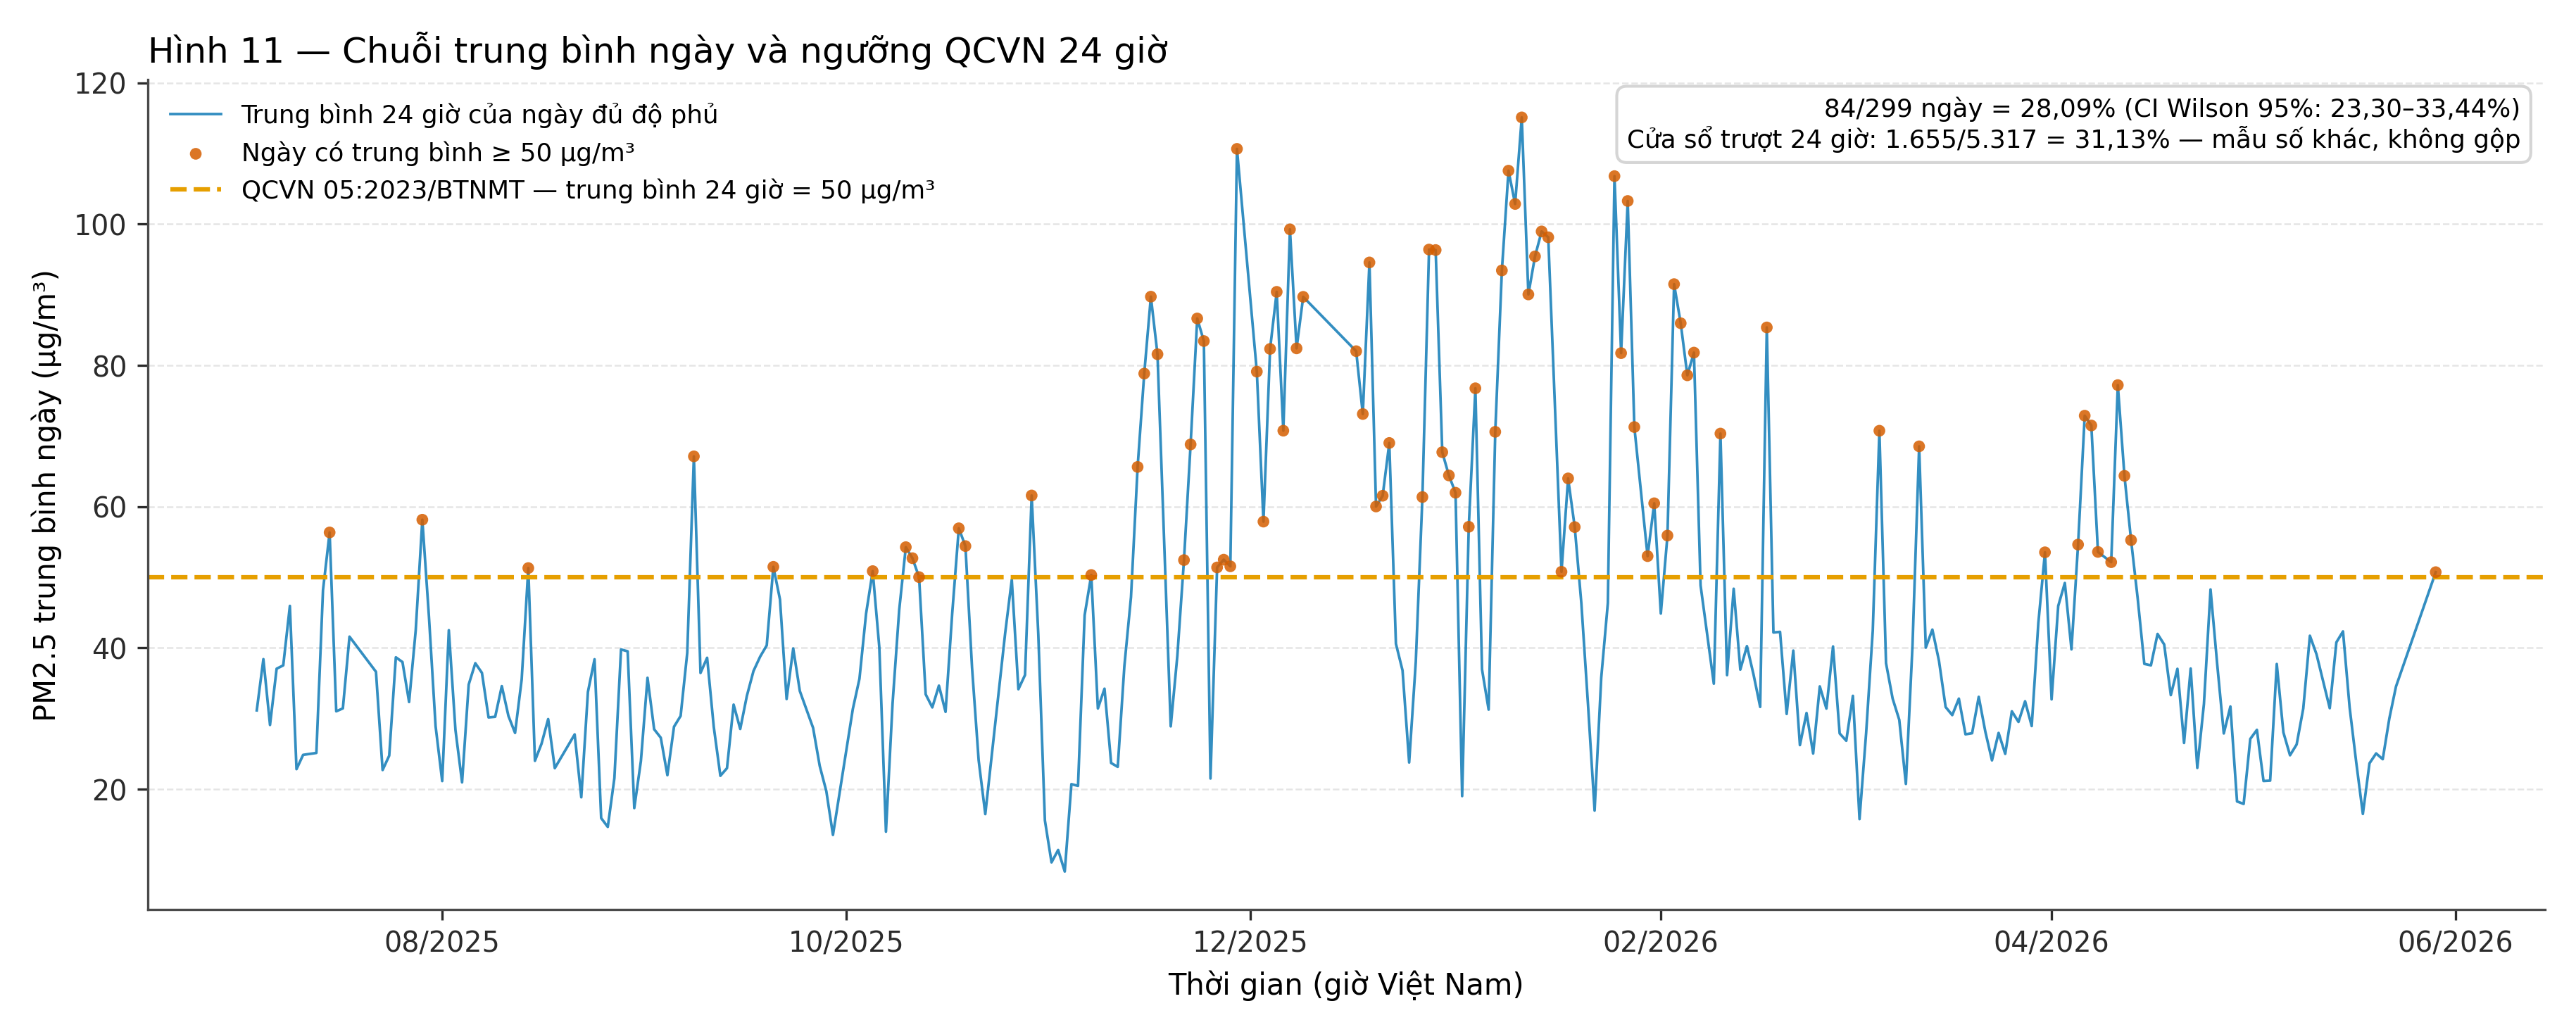

In [17]:
display_image(Image(filename=str(FIGURES["qcvn"]), width=760))


---

## 8. Kiểm tra độ nhạy — kết luận có phụ thuộc giả định độc lập?

Hai phép thử dưới đây **exploratory**, không thuộc family xác nhận nào, và p của
chúng **không** được hiệu chỉnh Holm. Mục đích duy nhất: xem kết luận ở mức ngày có
còn khi phân tích ở mức tuần — nơi tự tương quan thấp hơn nhiều.

### 8.1. Ghép cặp theo tuần cho weekday/weekend

Mỗi tuần ISO đủ điều kiện (≥ 3 ngày trong tuần và ≥ 2 ngày cuối tuần) cho **một**
chênh lệch. Cách này loại bỏ biến thiên "tuần này bẩn hơn tuần kia" — thứ tự tương
quan mạnh nhất còn lại sau khi đã lấy trung bình ngày.

### 8.2. Kruskal-Wallis trên trung bình tuần theo mùa

Nếu khác biệt mùa chỉ là hệ quả của việc coi từng ngày là độc lập, phép thử ở mức
tuần sẽ yếu đi rõ rệt. Ở mức tuần cỡ mẫu nhỏ hơn nhiều nên power thấp — p không có
ý nghĩa **không** phủ định kết quả mức ngày.


In [18]:
paired = sensitivity["paired_weeks"]
weekly_season = sensitivity["season_weekly"]["weekly_kruskal"]

print("8.1. Ghép cặp theo tuần (weekday − weekend)")
print(f"  Số tuần đủ điều kiện: {format_int_vi(paired['n_weeks'])} "
      f"(≥ {paired['min_weekdays']} ngày trong tuần, ≥ {paired['min_weekend_days']} ngày cuối tuần)")
print(f"  Trung vị chênh lệch: {format_number_vi(paired['median_difference'])} µg/m³, "
      f"CI 95% {ci_text(paired['ci'])}")
print(f"  Tỷ lệ tuần có weekday cao hơn: {pct(paired['share_weekday_higher'], 1)}")
print(f"  Wilcoxon trên {format_int_vi(paired['test']['n'])} chênh lệch tuần: "
      f"W = {format_number_vi(paired['test']['statistic'], 1)}, "
      f"p = {p_text(paired['test']['p_value'])}, r = {format_number_vi(paired['test']['effect_size'], 4)}")
print(f"  → {'bác bỏ' if paired['test']['p_value'] < ALPHA else 'không bác bỏ'} H₀ ở α = {ALPHA}")

print()
print("8.2. Kruskal-Wallis trên trung bình tuần theo mùa")
print(f"  Số tuần dùng được: {format_int_vi(sensitivity['season_weekly']['n_weeks'])}")
print(f"  H = {format_number_vi(weekly_season['statistic'], 3)} · df = {weekly_season['df']} · "
      f"p = {p_text(weekly_season['p_value'])} · ε² = {format_number_vi(weekly_season['effect_size'], 4)}")

assert paired["n_weeks"] < n_days
assert weekly_season["n"] < n_days


8.1. Ghép cặp theo tuần (weekday − weekend)
  Số tuần đủ điều kiện: 40 (≥ 3 ngày trong tuần, ≥ 2 ngày cuối tuần)
  Trung vị chênh lệch: −2,70 µg/m³, CI 95% [−8,61; 3,13]
  Tỷ lệ tuần có weekday cao hơn: 37,5%
  Wilcoxon trên 40 chênh lệch tuần: W = 315,0, p = 0,2064, r = −0,2317
  → không bác bỏ H₀ ở α = 0.05

8.2. Kruskal-Wallis trên trung bình tuần theo mùa
  Số tuần dùng được: 48
  H = 19,310 · df = 3 · p = 0,0002 · ε² = 0,4109


**Đọc kết quả.** Phép thử ghép cặp tuần cho cùng kết luận với Mann-Whitney ở mục 6
(không bác bỏ H₀), nên kết luận weekday/weekend **không** phải sản phẩm của giả định
độc lập. Phép thử mùa ở mức tuần vẫn bác bỏ H₀, củng cố kết luận mùa. Nếu hai phép
thử này **đổi chiều** so với mức ngày, kết luận đúng phải là "không ổn định" — và
điều đó phải được viết ra chứ không bị bỏ qua.


---

## 9. Đọc p-value cho đúng (task 5.7)

p-value là xác suất **của dữ liệu, có điều kiện H₀ đúng** — không phải xác suất H₀
đúng, cũng không phải xác suất kết quả lặp lại. Bốn sai lầm thường gặp:

| Sai lầm | Vì sao sai | Cách đọc đúng trong báo cáo này |
|---|---|---|
| "p là xác suất H₀ đúng" | p tính **dưới giả định H₀**; nó không phải xác suất hậu nghiệm | Chỉ nói "dữ liệu không tương thích với H₀ ở mức α" |
| "1 − p là xác suất H₁ đúng" | H₁ thường là giả thuyết hợp, không có phân phối tiên nghiệm | Không gán xác suất cho H₁ |
| "p nhỏ = hiệu ứng lớn" | p phụ thuộc cỡ mẫu; n ≈ 300 đủ làm hiệu ứng nhỏ có ý nghĩa | Luôn đọc kèm effect size và CI |
| "p > α = không có hiệu ứng" | Đó là "không đủ bằng chứng", không phải bằng chứng không | Nêu rõ MDE / giới hạn power của từng phép kiểm |

**Power = 1 − β.** Báo cáo không tuyên bố power định tính mà dùng **MDE** cho phép
so sánh hai nhóm (mục 6). Với bài toán cảnh báo, sai lầm loại II (bỏ lọt một đợt ô
nhiễm) tốn kém hơn sai lầm loại I — nên ngưỡng vận hành của mô hình ở Issue #13 sẽ
được chọn theo **Recall**, không theo Accuracy.


---

## 10. Prior probability và bẫy base-rate (task 5.8)

Trong 299 ngày đủ độ phủ, số ngày có trung bình ≥ 50 µg/m³ cho ta **prior** của bài
toán phân loại "ngày ô nhiễm" ở Issue #13. Đây là con số quan trọng vì nó quyết
định **baseline Accuracy**: một bộ phân loại luôn dự đoán "không ô nhiễm" đã đạt
Accuracy xấp xỉ `1 − prior` mà không học được gì.

Prior còn **dịch chuyển** giữa Train và Test vì điểm cắt `2026-01-15` rơi vào giữa
mùa đông. Hệ quả đó thuộc Issue #13 và phải xử lý bằng Recall + PR-AUC, không bằng
Accuracy. Cell dưới tính prior theo đúng điểm cắt đã nghiệm thu — **không** hardcode
lại ngày cắt, mà đọc từ `scripts/verify_claims.py`.


In [19]:
from scripts.verify_claims import SPLIT_TIMESTAMP

panel_over = panel["pm25_mean"] >= QCVN_2023_PM25_24H_LIMIT
in_train = panel["date"] < SPLIT_TIMESTAMP

prior_rows = []
for label, mask in (
    ("Train", in_train),
    ("Test", ~in_train),
    ("Toàn bộ giai đoạn", pd.Series(True, index=panel.index)),
):
    n_part = int(mask.sum())
    k_part = int((panel_over & mask).sum())
    prior_rows.append({
        "Phân đoạn": label,
        "n ngày": format_int_vi(n_part),
        "Ngày ≥ 50 µg/m³": format_int_vi(k_part),
        "Prior": pct(k_part / n_part) if n_part else "—",
        "Accuracy của 'luôn không ô nhiễm'": pct(1 - k_part / n_part) if n_part else "—",
    })
display(pd.DataFrame(prior_rows))

print(f"Điểm cắt Issue #7: {SPLIT_TIMESTAMP}")
print(f"→ Prior toàn giai đoạn: {context['panel_days_over']}/{context['panel_days']} "
      f"= {pct(context['panel_share'])}, khớp với mục 7.3.")
assert int(panel_over.sum()) == context["panel_days_over"]
assert int(in_train.sum()) + int((~in_train).sum()) == n_days


,Phân đoạn,n ngày,Ngày ≥ 50 µg/m³,Prior,Accuracy của 'luôn không ô nhiễm'
0,Train,174,55,"31,61%","68,39%"
1,Test,125,29,"23,20%","76,80%"
2,Toàn bộ giai đoạn,299,84,"28,09%","71,91%"


Điểm cắt Issue #7: 2026-01-15 00:00:00+07:00
→ Prior toàn giai đoạn: 84/299 = 28,09%, khớp với mục 7.3.


---

## 11. Giới hạn khoa học

1. **Một chu kỳ mùa, một trạm.** Dải 07/2025–07/2026 chỉ chứa một vòng mùa và toàn bộ dữ liệu đến từ một trạm đô thị. Khác biệt theo mùa là mô tả của **giai đoạn này**, không ngoại suy được sang năm khác hay trạm khác.
2. **Tự tương quan chưa được hiệu chỉnh vào p-value.** p của bốn kiểm định xác nhận vẫn dựa trên giả định độc lập; block bootstrap chỉ sửa khoảng tin cậy. p được đọc là **chỉ báo độ tương thích**, không phải bằng chứng chính xác tuyệt đối.
3. **Block bootstrap là xấp xỉ.** Block 7 ngày giữ cấu trúc tuần nhưng không mô phỏng được phụ thuộc dài hạn (lag 14 vẫn còn tương quan). Với so sánh hai nhóm, resample theo từng nhóm bỏ qua tương quan chéo nhóm — kiểm tra ghép cặp theo tuần ở mục 8.1 là biện pháp bù.
4. **Ngưỡng 18/24 giờ** là quy ước phân tích (độ phủ 75%), không phải điều khoản QCVN. Đổi ngưỡng sẽ đổi n; bảng nhật ký lọc ở mục 1 làm việc đổi ngưỡng trở nên minh bạch.
5. **QCVN 05:2023/BTNMT quy định ở điều kiện chuẩn** (µg/Nm³, 25 °C, 760 mmHg), còn trạm OpenAQ báo nồng độ môi trường (µg/m³). So sánh định lượng với ngưỡng vì vậy là **xấp xỉ**.
6. **Không có kết luận nhân quả.** Khác biệt theo mùa/ngày trong tuần là liên hệ thống kê; nguồn phát thải, khí tượng và điều kiện biên không được phân tách ở đây.

Ngoài ra, **bất nhất trong mô tả Issue #11** (trộn tử số cửa sổ trượt 24h với mẫu
số toàn bộ dòng giờ) đã được xử lý bằng cách trình bày **hai mẫu số tách bạch** ở
mục 7.3, kèm ví dụ về phép ghép sai. Không có tỷ lệ nào trong báo cáo dùng tử số
và mẫu số khác đơn vị.


---

## 12. Tái lập và artifact

Notebook ghi `reports/inference_results.md` bằng `render_inference_report(results)`
— cùng một payload đang hiển thị ở trên. Cell cuối:

1. Ghi báo cáo và đọc lại, xác nhận round-trip byte-identical.
2. Đối chiếu **chéo** các con số then chốt giữa notebook và báo cáo bằng helper định
   dạng cục bộ. Nếu báo cáo dùng số khác hoặc định dạng khác, phép so chuỗi thất bại.
3. Liệt kê artifact kèm kích thước để chứng minh tệp thực sự được ghi.

Mọi con số tái lập được với seed **42** và **1.000** lặp bootstrap. Sai khác duy
nhất có thể có là phiên bản NumPy/SciPy (đã ghi ở đầu báo cáo).


In [20]:
report_text = render_inference_report(results)
DEFAULT_REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)
DEFAULT_REPORT_PATH.write_text(report_text, encoding="utf-8")

# 1) Round-trip: đọc lại phải khớp từng ký tự.
assert DEFAULT_REPORT_PATH.read_text(encoding="utf-8") == report_text

# 2) Đối chiếu chéo notebook ↔ báo cáo trên các con số then chốt.
checks = {
    "p thô mùa": p_text(tests["season_kruskal"]["p_value"]),
    "p Holm mùa": p_text(tests["season_kruskal"]["p_holm"]),
    "p thô weekday": p_text(tests["weekday_mannwhitney"]["p_value"]),
    "p thô QCVN 24h": p_text(tests["qcvn_24h_wilcoxon"]["p_value"]),
    "p Holm QCVN 24h": p_text(tests["qcvn_24h_wilcoxon"]["p_holm"]),
    "p thô QCVN năm": p_text(tests["qcvn_annual_ttest"]["p_value"]),
    "p Holm QCVN năm": p_text(tests["qcvn_annual_ttest"]["p_holm"]),
    "CI weekday": ci_text(tests["weekday_mannwhitney"]["ci"]),
    "ε² mùa": format_number_vi(tests["season_kruskal"]["effect_size"], 4),
    "r_rb weekday": format_number_vi(tests["weekday_mannwhitney"]["effect_size"], 4),
    "r QCVN 24h": format_number_vi(tests["qcvn_24h_wilcoxon"]["effect_size"], 4),
    "Cohen's d QCVN năm": format_number_vi(tests["qcvn_annual_ttest"]["effect_size"], 4),
    "n_eff": format_number_vi(dependence["daily_effective_n"]["n_effective"], 1),
    "tỷ lệ ngày vượt": pct(context["panel_share"]),
}
missing = {name: token for name, token in checks.items() if token not in report_text}
assert not missing, f"Báo cáo thiếu/khác các token: {missing}"

# 3) Artifact thực sự tồn tại.
artifact_rows = [("Báo cáo", DEFAULT_REPORT_PATH, len(report_text))]
for key, filename in INFERENCE_FIGURES.items():
    path = FIGURES[key]
    assert path.name == filename
    artifact_rows.append((f"Hình ({key})", path, path.stat().st_size))

display(pd.DataFrame(
    [(label, str(path.relative_to(REPO_ROOT)), size) for label, path, size in artifact_rows],
    columns=["Artifact", "Đường dẫn", "Kích thước (bytes)"],
))
print(f"✓ Đã đối chiếu {len(checks)} token giữa notebook và báo cáo — không lệch.")
print(f"✓ Đã ghi {DEFAULT_REPORT_PATH.name} ({format_int_vi(len(report_text))} ký tự).")


,Artifact,Đường dẫn,Kích thước (bytes)
0,Báo cáo,reports\inference_results.md,15637
1,Hình (distribution),figures\FIG-08.png,341849
2,Hình (season),figures\FIG-09.png,139798
3,Hình (weekday),figures\FIG-10.png,206950
4,Hình (qcvn),figures\FIG-11.png,452442
5,Hình (autocorrelation),figures\FIG-12.png,183292


✓ Đã đối chiếu 14 token giữa notebook và báo cáo — không lệch.
✓ Đã ghi inference_results.md (15.637 ký tự).


---

## Tổng kết Issue #11

| Hạng mục yêu cầu | Nơi đáp ứng |
|---|---|
| Chẩn đoán phân phối, không mặc định chuẩn | Mục 2 (skewness, kurtosis, Shapiro-Wilk, D'Agostino, Q-Q) |
| Ba nhóm kiểm định | Mục 5 (mùa), 6 (weekday/weekend), 7 (QCVN 24h + năm) |
| Đúng chu kỳ trung bình của ngưỡng | Mục 7.1 (24h = 50) và 7.2 (năm = 25), tách biệt |
| Bộ bốn: thống kê + p + effect size + CI 95% | Mục 4.4, 5, 6, 7 |
| H₀/H₁ và lý do chọn phép kiểm | Mục 4.1, 5.1, 6.1, 7.1, 7.2 |
| n và số quan sát bị loại | Mục 1.2 (299 giữ / 52 loại), từng kiểm định ở mục 4.3 |
| Holm báo cả p gốc và p hiệu chỉnh | Mục 4.4 (family xác nhận), 5.3 (family hậu định riêng) |
| α = 0,05; 1.000 bootstrap; seed 42 | Mục 0, assert trong mục 0.1 |
| Xử lý tự tương quan | Mục 3 (ACF, n_eff, block bootstrap 7 ngày, kiểm tra tuần) |
| Giới hạn khi giả định không bảo đảm | Mục 3.3, 6.2 (MDE), 11 |
| Không đổi chronological split | Mục 1.2, 10 (đọc `SPLIT_TIMESTAMP`) |
| Đầu ra tái lập | Mục 12 (round-trip + đối chiếu chéo + artifact) |

**Deliverable:** `reports/inference_results.md`, `figures/FIG-08.png` … `FIG-12.png`
(hình bổ sung của Issue #11, không thuộc bộ bảy hình ấn phẩm của Issue #9).
